# UCCD2063 Artificial Intelligence Techniques

## Introduction

The goal of this project is to build and evaluate machine learning models on the given dataset.  
The objectives are:
- To preprocess the dataset by handling missing values, scaling, and encoding.  
- To implement multiple machine learning algorithms and compare their performance.  
- To evaluate the models using metrics such as accuracy, precision, recall, F1-score, and confusion matrix.  
- To analyze feature importance to gain insights into which variables contribute most to predictions.

By the end, the best-performing model will be identified, along with recommendations for improvement and future work.

# Abstract

This notebook presents an end-to-end workflow for predicting employee attrition, structured into four main sections followed by a conclusion.

**Section 1 – Data Understanding & Preparation**  
We analyze a dataset of 5,000 employees with 19 features, including demographics, job roles, experience, performance ratings, satisfaction, and salary. Data integrity is verified through sanity checks separating numeric, nominal, and ordinal variables. Preprocessing strategies create three experimental setups:  
- **Plan A**: Baseline using all features.  
- **Plan B**: Outlier removal with refined preprocessing.  
- **Plan C**: Combined approach — both removing outliers and dropping problematic features to reduce overfitting and enhance generalization.  

**Section 2 – Exploratory Data Analysis (EDA)**  
Statistical summaries and visualizations highlight relationships between predictors and attrition. Key insights include the influence of job role, satisfaction score, salary category, overtime, and education on attrition likelihood.

**Section 3 – Modeling Approaches**  
Eight machine learning models are trained across Plans A–C: Logistic Regression, Random Forest, Gradient Boosting, XGBoost, Support Vector Machine, k-Nearest Neighbor, Naive Bayes, and SGD Classifier. Hyperparameter tuning and cross-validation are applied for robust evaluation.

**Section 4 – Model Evaluation & Comparison**  
Models are benchmarked using validation score, test accuracy, test F1 score, and training time.  
- **Plan A** achieved strong validation scores but showed overfitting.  
- **Plan B** improved stability through outlier removal, but overfitting persisted due to high-cardinality features.  
- **Plan C** delivered the most generalizable results by combining outlier removal with feature dropping. The **SGD Classifier under Plan C** emerged as the top model (≈82.5% test accuracy, ≈81.5% weighted F1) with efficient training time.  

**Conclusion**  
While Plans A and B performed reasonably well, they suffered from overfitting. Plan C proved to be the most effective strategy, balancing accuracy, F1 score, and computational efficiency. The final recommended model is the **SGD Classifier under Plan C**. Future work aims to extend this framework with IoT-based sensor data, AI-driven APIs, personalized recommendations, and multi-user centralized database integration for real-world deployment.



## 1. Imports & Setup

Before starting the analysis, we install and import the required libraries.  
- **xgboost** is installed for gradient boosting models.  

In [1]:
!pip install xgboost --quiet

### Importing Libraries

We import the required Python libraries for data handling, visualization, preprocessing, model training, and evaluation.  
This includes:
- **Warnings:** Suppressed to keep the output clean using `warnings.filterwarnings('ignore')`.  
- **Data Handling:** `pandas` and `numpy` for loading, manipulating, and analyzing datasets.  
- **Visualization:** `matplotlib.pyplot` and `seaborn` for plotting charts and inspecting data distributions.  
- **Statistical Analysis:** `scipy.stats` for statistical operations and outlier detection.  
- **Preprocessing & Pipelines:** `scikit-learn` modules for scaling, encoding, splitting datasets, and building reusable pipelines.  
- **Model Training & Evaluation:** Includes a variety of classifiers (`LogisticRegression`, `SGDClassifier`, `RandomForestClassifier`, `GradientBoostingClassifier`, `SVC`, `KNeighborsClassifier`, `GaussianNB`) and evaluation metrics (`accuracy_score`, `f1_score`, `roc_auc_score`, `classification_report`, `confusion_matrix`).  
- **Hyperparameter Tuning:** `GridSearchCV` and `RandomizedSearchCV` for finding the best model parameters.  
- **Advanced Models:** Optional `xgboost` import for gradient boosting; includes a check in case the library is not installed.  



In [2]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix

# Models
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# xgboost import (may require installation)
try:
    import xgboost as xgb
except Exception as e:
    xgb = None
    print('xgboost not available. Install with: pip install xgboost')

## 2. Load Data

The dataset `Tech_employee_salary.csv` is loaded into a Pandas DataFrame.  
We also define the target column (`salary_category`) for prediction.  
This dataset contains employee profile information (features) and the corresponding salary category (Low, Medium, High).

In [3]:
# === USER INPUT ===
TARGET_COL = "salary_category"   

#load data
df = pd.read_csv("Tech_employee_salary.csv")

# Preview first 5 rows
df.head()

,employee_id,years_experience,gender,education_level,job_title,location,work_mode,primary_language,performance_rating,projects_completed,team_size,overtime_hours_month,certifications_count,github_contributions,birth_month,bonus_percentage,stock_options,remote_work_days,satisfaction_score,salary_category
0,EMP_0001,11,male,PhD,Full Stack Developer,"Chicago, IL",On-site,C++,3.2,19,9,15,6,370,March,NaN,Yes,2.0,3.7,Medium
1,EMP_0002,20,male,Bachelor,Frontend Developer,Remote,Hybrid,C++,4.1,30,13,7,8,523,March,13.0,Yes,3.0,3.1,Medium
2,EMP_0003,21,male,Bachelor,Engineering Manager,"Toronto, CA",Remote,Rust,3.9,32,10,1,9,555,September,10.0,No,3.0,4.9,High
3,EMP_0004,7,female,PhD,Data Scientist,"Los Angeles, CA",Remote,TypeScript,3.3,17,4,0,4,253,February,24.0,No,1.0,NaN,Medium
4,EMP_0005,10,female,Bachelor,Engineering Manager,"London, UK",Remote,Python,3.6,15,3,0,4,255,November,15.0,Yes,5.0,2.8,High


## 3. Data Exploration

### Initial Dataset Inspection

Before performing detailed exploration, we normalize the column names for consistency  
(converting to lowercase, stripping spaces).  

We then check the dataset’s **shape** (rows × columns) and preview the first few rows to understand the structure.


In [4]:
# Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Head & shape
print('Shape:', df.shape)
display(df.head())

Shape: (5000, 20)


,employee_id,years_experience,gender,education_level,job_title,location,work_mode,primary_language,performance_rating,projects_completed,team_size,overtime_hours_month,certifications_count,github_contributions,birth_month,bonus_percentage,stock_options,remote_work_days,satisfaction_score,salary_category
0,EMP_0001,11,male,PhD,Full Stack Developer,"Chicago, IL",On-site,C++,3.2,19,9,15,6,370,March,NaN,Yes,2.0,3.7,Medium
1,EMP_0002,20,male,Bachelor,Frontend Developer,Remote,Hybrid,C++,4.1,30,13,7,8,523,March,13.0,Yes,3.0,3.1,Medium
2,EMP_0003,21,male,Bachelor,Engineering Manager,"Toronto, CA",Remote,Rust,3.9,32,10,1,9,555,September,10.0,No,3.0,4.9,High
3,EMP_0004,7,female,PhD,Data Scientist,"Los Angeles, CA",Remote,TypeScript,3.3,17,4,0,4,253,February,24.0,No,1.0,NaN,Medium
4,EMP_0005,10,female,Bachelor,Engineering Manager,"London, UK",Remote,Python,3.6,15,3,0,4,255,November,15.0,Yes,5.0,2.8,High


### Data Types and Non-null Values

To better understand the dataset, we check the **data types** of each column and the number of **non-null values**.  
This helps to:
- Identify whether a feature is numerical, categorical, or textual.  
- Detect columns with missing values.  
- Plan suitable preprocessing steps (encoding for categorical data, imputation for missing values).


In [5]:
# Dtypes and non-null counts
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           5000 non-null   object 
 1   years_experience      5000 non-null   int64  
 2   gender                5000 non-null   object 
 3   education_level       5000 non-null   object 
 4   job_title             5000 non-null   object 
 5   location              5000 non-null   object 
 6   work_mode             5000 non-null   object 
 7   primary_language      5000 non-null   object 
 8   performance_rating    5000 non-null   float64
 9   projects_completed    5000 non-null   int64  
 10  team_size             5000 non-null   int64  
 11  overtime_hours_month  5000 non-null   int64  
 12  certifications_count  5000 non-null   int64  
 13  github_contributions  5000 non-null   int64  
 14  birth_month           5000 non-null   object 
 15  bonus_percentage     

None

### NaN Values, Empty String, and Placeholder Check

It is important to check whether the dataset contains missing values or inconsistencies:  

1. **Null Value Check** – Identifies columns with official `NaN` values.  
2. **Empty String or Placeholder Check** – Even if no `NaN` exists, some columns may contain blanks or placeholder values (e.g., `" "`, `"NA"`, `"-"`).  


**Status meanings in the output table:**  
- **True** → The column has **null value**. (for null value check) 
- **OK** → The column has **no NaN values and no empty strings**.  (for NaN and empty strings check)
- **Check** → The column contains **NaN values or empty strings** and needs attention.  (for NaN and empty strings check)


In [6]:
# Checking for null value
print("Null value status:\n")
print(df.isnull().any())

Null value status:

employee_id             False
years_experience        False
gender                  False
education_level         False
job_title               False
location                False
work_mode               False
primary_language        False
performance_rating      False
projects_completed      False
team_size               False
overtime_hours_month    False
certifications_count    False
github_contributions    False
birth_month             False
bonus_percentage         True
stock_options            True
remote_work_days         True
satisfaction_score       True
salary_category         False
dtype: bool


In [7]:
# Checking for NaN and empty strings
print(f"{'Column':<25} {'NaN Count':<10} {'Empty String Count':<12} Status")
print("-"*60)

for col in df.columns:
    n_nan = df[col].isna().sum()
    n_empty = (df[col].astype(str).str.strip() == "").sum()

    status = "OK" if n_nan == 0 and n_empty == 0 else "Check"
    
    print(f"{col:<25} {n_nan:<10} {n_empty:<12} {status}")


Column                    NaN Count  Empty String Count Status
------------------------------------------------------------
employee_id               0          0            OK
years_experience          0          0            OK
gender                    0          0            OK
education_level           0          0            OK
job_title                 0          0            OK
location                  0          0            OK
work_mode                 0          0            OK
primary_language          0          0            OK
performance_rating        0          0            OK
projects_completed        0          0            OK
team_size                 0          0            OK
overtime_hours_month      0          0            OK
certifications_count      0          0            OK
github_contributions      0          0            OK
birth_month               0          0            OK
bonus_percentage          403        0            Check
stock_options            

### Missing Values per Column

To quantify the extent of missing data, we calculate the **total number of missing values in each column** and display them in descending order.  
This highlights which features require special handling during preprocessing later (imputation or removal).


In [8]:
# Missing values per column (sorted)
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing>0])

bonus_percentage      403
satisfaction_score    254
stock_options         201
remote_work_days       89
dtype: int64

### Duplicate Rows Check
Detecting duplicated rows ensures there are no repeated observations in the dataset.  
Removing duplicates helps avoid **biased model training**.


In [9]:
print("Number of duplicated rows:", df.duplicated().sum())

Number of duplicated rows: 0


### Feature Type Breakdown

The dataset consists of **20 features** in total: **19 input features** plus **1 target variable** (`salary_category`).

- **10 numeric features**: `years_experience`, `performance_rating`, `projects_completed`, `team_size`, `overtime_hours_month`, `certifications_count`, `github_contributions`, `bonus_percentage`, `remote_work_days`, `satisfaction_score`.  
- **8 nominal categorical features**: `employee_id`, `gender`, `job_title`, `location`, `work_mode`, `primary_language`, `birth_month`, `stock_options`.  
- **1 ordinal categorical feature**: `education_level`.  

This breakdown is important for guiding preprocessing:  
- **Numeric features** may require scaling or transformations (e.g., to handle skewness).  
- **Nominal categorical features** require encoding (e.g., one-hot encoding).  
- **Ordinal features** such as `education_level` should be encoded to preserve their natural order.

#### Sanity Checks for Feature Types

Before processing, it is important to ensure that the classification of features into **numeric**, **nominal**, and **ordinal** is consistent and mutually exclusive, with no overlaps.


In [10]:


# input columns (exclude target)
input_cols = [c for c in df.columns if c != TARGET_COL]
total_input = len(input_cols)

# numeric (only those among input columns)
numeric = [c for c in df.select_dtypes(include=['number']).columns if c in input_cols]

# all categorical = input columns that are not numeric
categorical_all = [c for c in input_cols if c not in numeric]

# manually define ordinal features 
ordinal = [c for c in ['education_level'] if c in df.columns]

# nominal = categorical minus ordinal
nominal = [c for c in categorical_all if c not in ordinal]

# print counts and names
print("Total input features:", total_input)
print("Numeric features:", len(numeric))
print("Nominal categorical features:", len(nominal))
print("Ordinal categorical features:", len(ordinal))
print()
print("Numeric:", numeric)
print("Nominal:", nominal)
print("Ordinal:", ordinal)

# sanity checks 
assert set(numeric).isdisjoint(nominal)
assert set(numeric).isdisjoint(ordinal)
assert set(nominal).isdisjoint(ordinal)
assert len(numeric) + len(nominal) + len(ordinal) == total_input, "Counts do not sum to total inputs!"




Total input features: 19
Numeric features: 10
Nominal categorical features: 8
Ordinal categorical features: 1

Numeric: ['years_experience', 'performance_rating', 'projects_completed', 'team_size', 'overtime_hours_month', 'certifications_count', 'github_contributions', 'bonus_percentage', 'remote_work_days', 'satisfaction_score']
Nominal: ['employee_id', 'gender', 'job_title', 'location', 'work_mode', 'primary_language', 'birth_month', 'stock_options']
Ordinal: ['education_level']


### Summary Statistics

To gain an overview of the dataset distribution, we generate descriptive statistics for **numerical**, **categorical**, and **ordinal** features using `.describe(include='all')`.

- **Numerical features** → mean, standard deviation, minimum, maximum, and quartiles. These help to detect skewness, spread, and potential outliers.  
- **Categorical (nominal) features** → count, number of unique values, most frequent category (`top`), and its frequency (`freq`). This helps identify class imbalances and high-cardinality variables.  
- **Ordinal features** → also summarized as categorical in `.describe()`, but their values carry a natural order (e.g., `education_level`). This order is important and will be preserved during preprocessing (e.g., ordinal encoding instead of one-hot).  


In [11]:
# Summary statistics (numeric and object)
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
employee_id,5000,5000,EMP_5000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
years_experience,5000.0,NaN,NaN,NaN,11.4858,6.362758,0.0,7.0,11.0,15.0,30.0
gender,5000,2,male,2526,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,5000,4,Bachelor,2432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_title,5000,16,UI/UX Designer,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,5000,13,"New York, NY",428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_mode,5000,3,On-site,1714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_language,5000,8,Swift,678,NaN,NaN,NaN,NaN,NaN,NaN,NaN
performance_rating,5000.0,NaN,NaN,NaN,3.16612,0.598665,1.0,2.8,3.2,3.6,5.0
projects_completed,5000.0,NaN,NaN,NaN,21.4426,7.062257,4.0,16.0,21.0,26.0,47.0


### Feature Type Breakdown

A pie chart illustrates the proportion of **numeric**, **nominal categorical**, and **ordinal categorical** features in the dataset.  
This visualization provides a quick overview of feature types and complements the earlier feature count table.  

- **Brown** → Numeric features  
- **Light Blue** → Nominal categorical features  
- **Orange** → Ordinal categorical features  


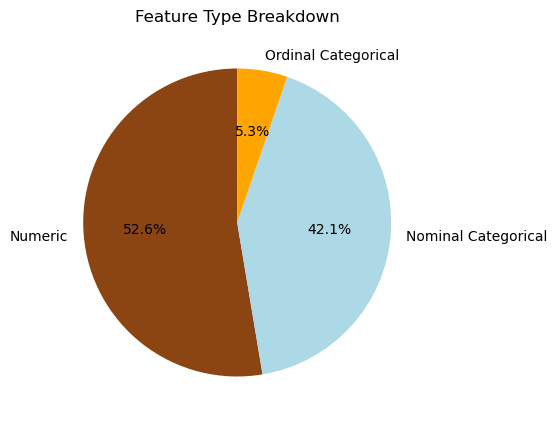

In [12]:
feature_types = {
    "Numeric": len(numeric),
    "Nominal Categorical": len(nominal),  
    "Ordinal Categorical": len(ordinal)
}

plt.figure(figsize=(5,5))
plt.pie(feature_types.values(), labels=feature_types.keys(), autopct='%1.1f%%', startangle=90, colors=['saddlebrown', 'lightblue', 'orange'])
plt.title("Feature Type Breakdown")
plt.show()


### Ordinal Feature Analysis

The feature `education_level` is ordinal and analyzed in multiple ways to capture both its categorical nature and its inherent order:

1. **Categorical-style view (countplot):**  
   Shows the distribution of salary categories within each education level.  
   Useful for detecting imbalances (e.g., many high school employees in low salary).  

2. **Numeric-style view (violin plot):**  
   Adds density information to show how education levels are spread across salary categories.  
   Highlights overlap and skew within each salary group.  

Together, these views confirm whether increasing education is linked with higher salary, both in distribution (categorical) and in trend (numeric).


### Ordinal Feature Distribution (Countplot)

The feature `education_level` is ordinal and carries a natural ordering (High School < Bachelor < Master < PhD).  
Unlike nominal categories, its order is meaningful and must be preserved during preprocessing.  

This plot shows the distribution of education levels across the target classes (`salary_category`).  
It highlights whether higher education levels are associated with higher salary categories.  


In [13]:
# basic checks
print("TARGET_COL in globals():", 'TARGET_COL' in globals())
try:
    print("TARGET_COL:", TARGET_COL)
except NameError:
    print("TARGET_COL is not defined")

print("'education_level' in df.columns:", 'education_level' in df.columns)

if 'education_level' in df.columns:
    print("dtype:", df['education_level'].dtype)
    print("unique values:", df['education_level'].dropna().unique())
    print("sample values:", df['education_level'].dropna().unique()[:10])

if 'education_level' in df.columns and 'TARGET_COL' in globals():
    print("target unique:", df[TARGET_COL].dropna().unique())


TARGET_COL in globals(): True
TARGET_COL: salary_category
'education_level' in df.columns: True
dtype: object
unique values: ['PhD' 'Bachelor' 'High School' 'Master']
sample values: ['PhD' 'Bachelor' 'High School' 'Master']
target unique: ['Medium' 'High' 'Low']


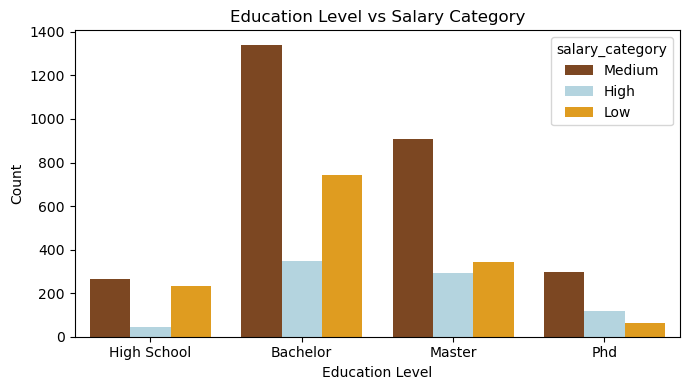

NaNs in education_level: 0
Unique values: ['Phd', 'Bachelor', 'High School', 'Master']
Categories (4, object): ['High School' < 'Bachelor' < 'Master' < 'Phd']


In [14]:

df['education_level'] = df['education_level'].str.strip().str.title()


desired_order = ["High School", "Bachelor", "Master", "Phd"]

df['education_level'] = pd.Categorical(
    df['education_level'],
    categories=desired_order,
    ordered=True
)



palette = ['saddlebrown', 'lightblue', 'orange']

plt.figure(figsize=(7,4))
sns.countplot(
    x='education_level',
    hue=TARGET_COL,
    data=df,
    order=desired_order,
    palette=palette
)
plt.title("Education Level vs Salary Category")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


print("NaNs in education_level:", df['education_level'].isna().sum())
print("Unique values:", df['education_level'].unique())



### Ordinal Feature as Numeric (Violin Plot)

The violin plot extends the boxplot by showing the **distribution density** of education levels within each salary category.  

This provides richer insights, highlighting overlaps or skewness in how education levels are spread across salary groups.

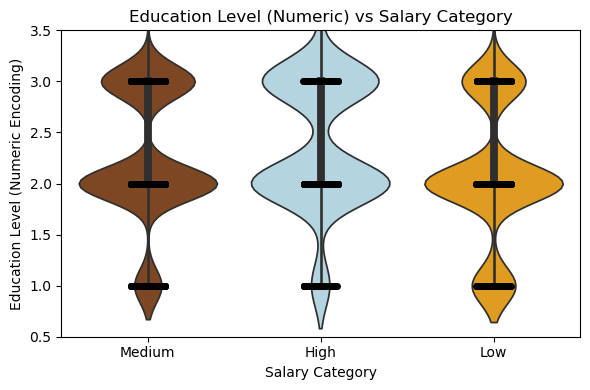

In [15]:
# Map ordinal to numeric
edu_map = {"High School": 1, "Bachelor": 2, "Master": 3, "Phd": 4}
df['education_level_num'] = df['education_level'].map(edu_map)

plt.figure(figsize=(6,4))
sns.violinplot(
    x=TARGET_COL,
    y='education_level_num',
    data=df,
    palette=palette
)

# Overlay individual points for clarity
sns.stripplot(
    x=TARGET_COL,
    y='education_level_num',
    data=df,
    color='black',
    size=5,
    jitter=True
)

# Stretch y-axis slightly for aesthetics
plt.ylim(0.5,3.5)
plt.title("Education Level (Numeric) vs Salary Category")
plt.xlabel("Salary Category")
plt.ylabel("Education Level (Numeric Encoding)")
plt.tight_layout()
plt.show()


### Feature Preprocessing Justification

During exploratory data analysis (EDA), input features were separated into three types:

1. **Numeric features** – continuous values, suitable for scaling.  
2. **Ordinal categorical features** – variables with a meaningful order
3. **Nominal categorical features** – variables without intrinsic order.  

Violin plots and variance analyses were conducted for ordinal features. These visualizations showed **limited variance** across categories, indicating that the ordering of ordinal features and distinctions between nominal categories would likely have minimal effect on model performance.  

Based on these observations, all categorical features were **treated as a single group** during model training, without explicitly separating ordinal and nominal features. This simplifies preprocessing while maintaining model performance, especially for tree-based models (Random Forest, XGBoost, Gradient Boosting), which can naturally handle categorical inputs after encoding.  

> Note: Numeric features were still scaled as appropriate, and categorical encoding ensured all categories were correctly represented.


### Categorical Feature Distribution

To understand the balance of categorical variables, we examine the **frequency counts** of their values.  
This helps to:  
- Detect dominant categories or class imbalance.  
- Identify rare categories that may need to be grouped together.  
- Guide encoding strategies (One-Hot Encoding, Target Encoding).  

Here, the categorical columns are explored.


In [16]:
# Value counts for key categorical columns
cat_cols = df.select_dtypes(include=['object','category']).columns.tolist()
for c in cat_cols:
    print('\n\nColumn:', c)
    display(df[c].value_counts().head(10))



Column: employee_id


employee_id
EMP_5000    1
EMP_0001    1
EMP_0002    1
EMP_0003    1
EMP_0004    1
EMP_0005    1
EMP_0006    1
EMP_0007    1
EMP_4984    1
EMP_4983    1
Name: count, dtype: int64



Column: gender


gender
male      2526
female    2474
Name: count, dtype: int64



Column: education_level


education_level
Bachelor       2432
Master         1546
High School     545
Phd             477
Name: count, dtype: int64

... (12 outputs left out)



Column: salary_category


salary_category
Medium    2810
Low       1387
High       803
Name: count, dtype: int64



Column: education_level_num


education_level_num
2    2432
3    1546
1     545
4     477
Name: count, dtype: int64

### Unique Values per Column for All Features
Checking the number of unique values in each column helps to identify **ID-like features**  
(`employee_id`) and low-variance features which may not contribute to predictions.


In [17]:
unique_counts = df.nunique().sort_values()
display(unique_counts)

gender                     2
stock_options              2
salary_category            3
work_mode                  3
education_level            4
education_level_num        4
remote_work_days           6
primary_language           8
birth_month               12
location                  13
team_size                 15
job_title                 16
certifications_count      16
bonus_percentage          21
years_experience          31
performance_rating        41
satisfaction_score        41
projects_completed        43
overtime_hours_month      56
github_contributions     867
employee_id             5000
dtype: int64

### Cardinality of Categorical Features
For categorical features, it is important to assess **how many distinct categories exist**.  
High-cardinality features (`job_title` with many unique values) can complicate encoding and increase model complexity.


In [18]:
cat_cols = df.select_dtypes(include=['object','category']).columns.tolist()
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique values")

employee_id: 5000 unique values
gender: 2 unique values
education_level: 4 unique values
job_title: 16 unique values
location: 13 unique values
work_mode: 3 unique values
primary_language: 8 unique values
birth_month: 12 unique values
stock_options: 2 unique values
salary_category: 3 unique values
education_level_num: 4 unique values


### Cardinality of Categorical Features (Visualization)

Cardinality refers to the number of **unique values** in a categorical feature.  
High-cardinality features (`job_title`) may complicate encoding and increase model complexity, while low-cardinality features (`gender`) are easier to encode.  

The bar chart below shows the unique category counts for each categorical feature.  


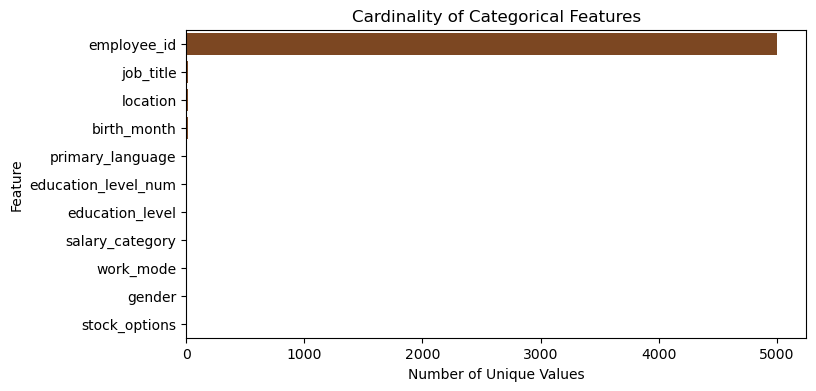

In [19]:
cardinality = df[cat_cols].nunique().sort_values(ascending=False)
plt.figure(figsize=(8,4))
sns.barplot(x=cardinality.values, y=cardinality.index, color="saddlebrown")
plt.title("Cardinality of Categorical Features")
plt.xlabel("Number of Unique Values")
plt.ylabel("Feature")
plt.show()


### Cardinality of Categorical Features (Excluding `employee_id`)

We plot the number of unique values (cardinality) for all categorical features, excluding `employee_id`, because it is unique for each record and would skew the chart.  

High-cardinality features may require special encoding strategies or grouping before model training.


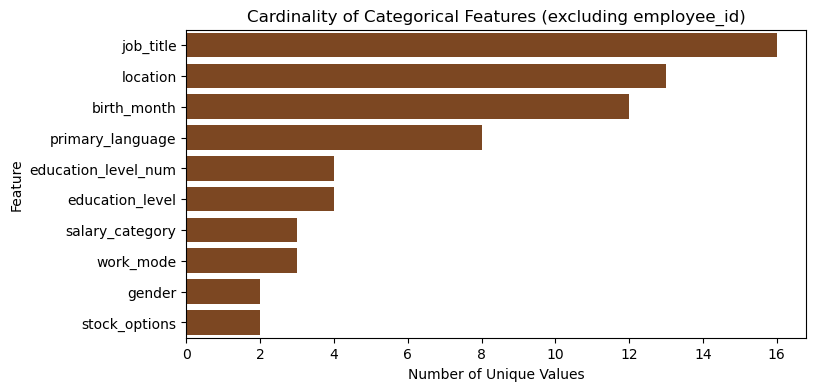

In [20]:
# Exclude employee_id from categorical features
cat_cols_excl_id = [col for col in cat_cols if col != 'employee_id']

# Calculate cardinality
cardinality = df[cat_cols_excl_id].nunique().sort_values(ascending=False)

# Plot
plt.figure(figsize=(8,4))
sns.barplot(x=cardinality.values, y=cardinality.index, color="saddlebrown")
plt.title("Cardinality of Categorical Features (excluding employee_id)")
plt.xlabel("Number of Unique Values")
plt.ylabel("Feature")
plt.show()


### Skewness of Numerical Features
Skewness measures the **asymmetry of feature distributions**.  
- A skewness near 0 indicates a fairly symmetric distribution.  
- Positive skewness indicates a **long right tail**.  
- Negative skewness indicates a **long left tail**.

In [21]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[num_cols].skew()

years_experience        0.535248
performance_rating      0.050709
projects_completed      0.415342
team_size               0.024475
overtime_hours_month    2.066300
certifications_count    0.406021
github_contributions    0.760804
bonus_percentage       -0.006374
remote_work_days       -0.004174
satisfaction_score      0.022447
dtype: float64

### Skewness of Numerical Features With KDE (Visualization)

Skewness measures the **asymmetry** of a distribution:  

- **Positive skew** → long tail to the right  
- **Negative skew** → long tail to the left  
- **Near zero** → roughly symmetric (normal-like)  

Visualizing numeric features with **histograms** and **KDE (Kernel Density Estimate) curves** makes skewness easier to detect.  

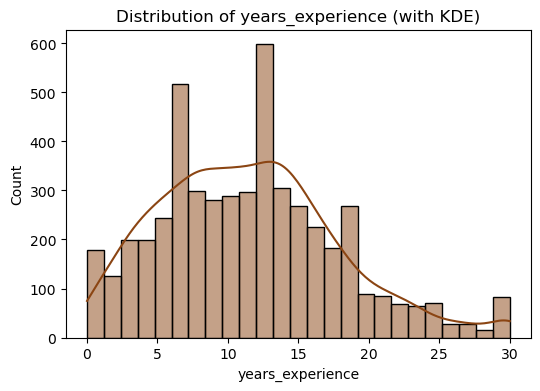

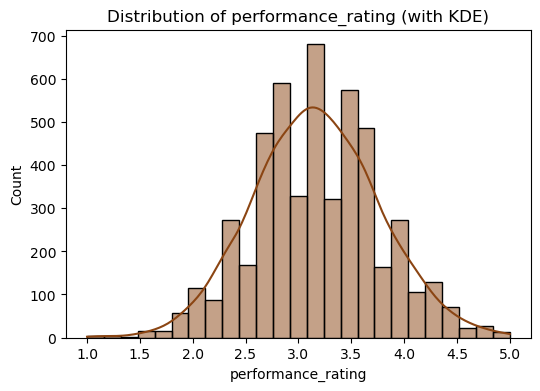

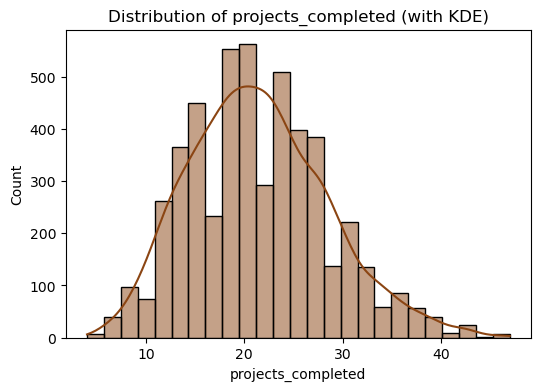

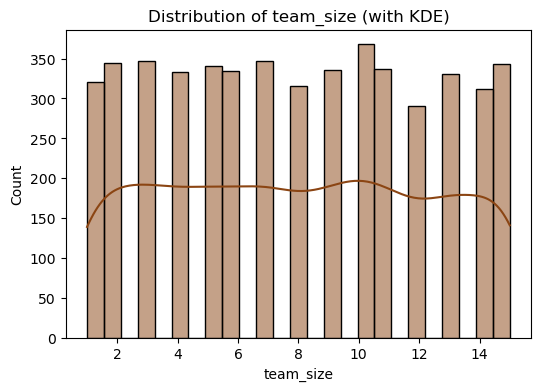

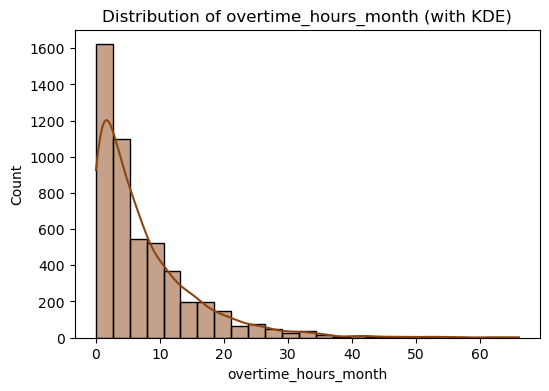

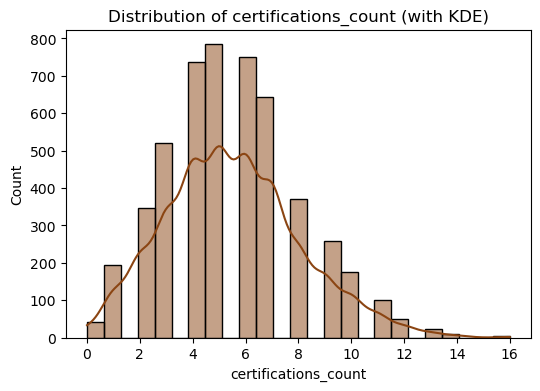

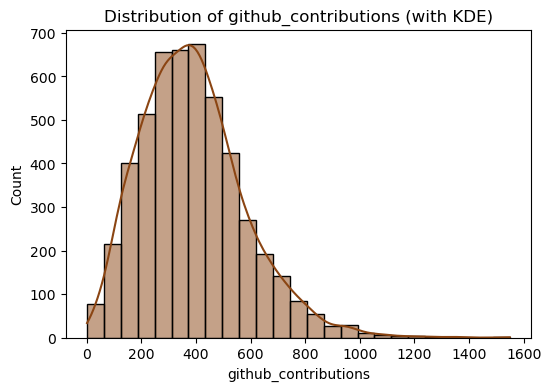

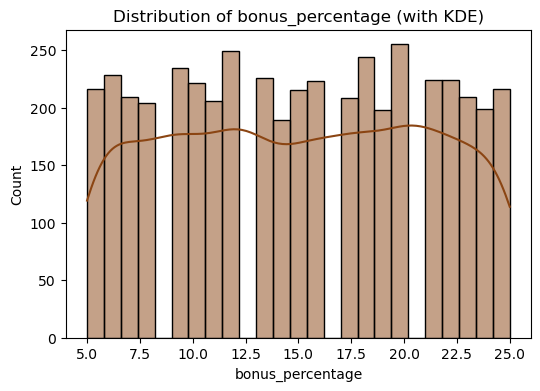

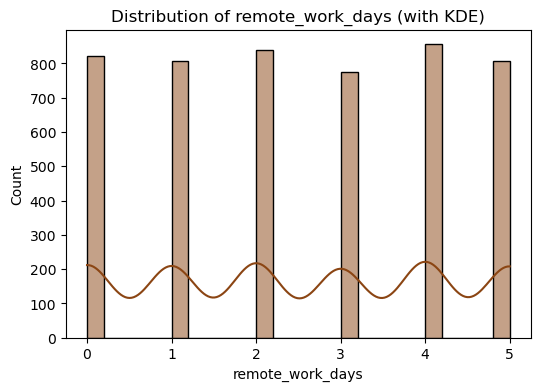

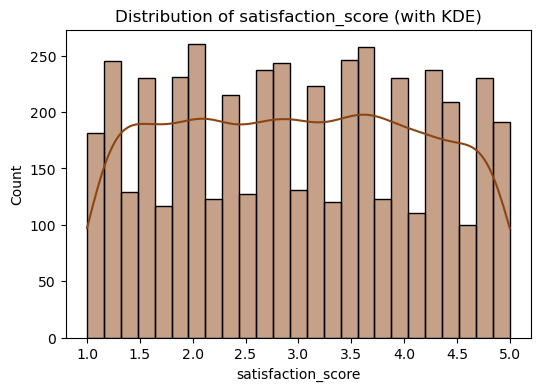

In [22]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=25, color="saddlebrown")
    plt.title(f"Distribution of {col} (with KDE)")
    plt.show()

## 4. Data Visualization

Use seaborn / matplotlib to visualize distributions, counts, and outliers. 

## Target Distribution Visualization
We begin by visualizing the **target variable (`salary_category`)** to check whether the dataset is balanced.  
Imbalanced classes can significantly affect model training and evaluation.


TARGET DISTRIBUTION


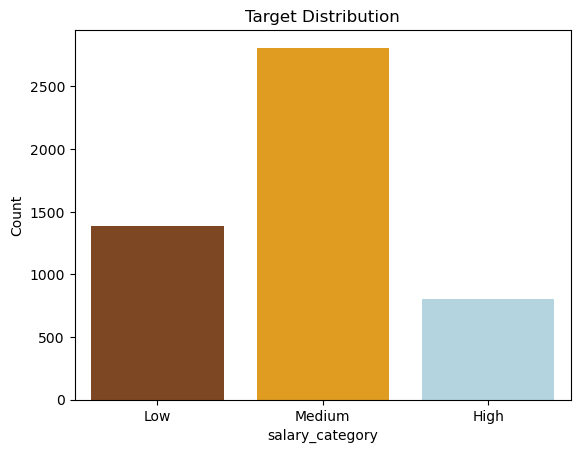


Counts per class:
salary_category
Medium    2810
Low       1387
High       803
Name: count, dtype: int64

Proportions per class:
salary_category
Medium    0.5620
Low       0.2774
High      0.1606
Name: proportion, dtype: float64


In [23]:
# ----------------------------
# Target Distribution
# ----------------------------
print("TARGET DISTRIBUTION")
palette = ['saddlebrown', 'orange', 'lightblue']

sns.countplot(x=TARGET_COL, data=df,  order=['Low', 'Medium', 'High'],  palette=palette)
plt.title("Target Distribution")
plt.xlabel(TARGET_COL)
plt.ylabel("Count")
plt.show()

print("\nCounts per class:")
print(df[TARGET_COL].value_counts())

print("\nProportions per class:")
print(df[TARGET_COL].value_counts(normalize=True))


## Numerical Features Visualization

### Numerical Feature Distributions Overview 
To understand the distribution of numerical variables, we plot histograms for all numeric columns in one figure to ease the comparison of viewing 
This helps identify patterns such as:
- **Normality or skewness** of distributions  
- **Presence of outliers**  
- **Potential data transformations** needed (log scaling for highly skewed data)

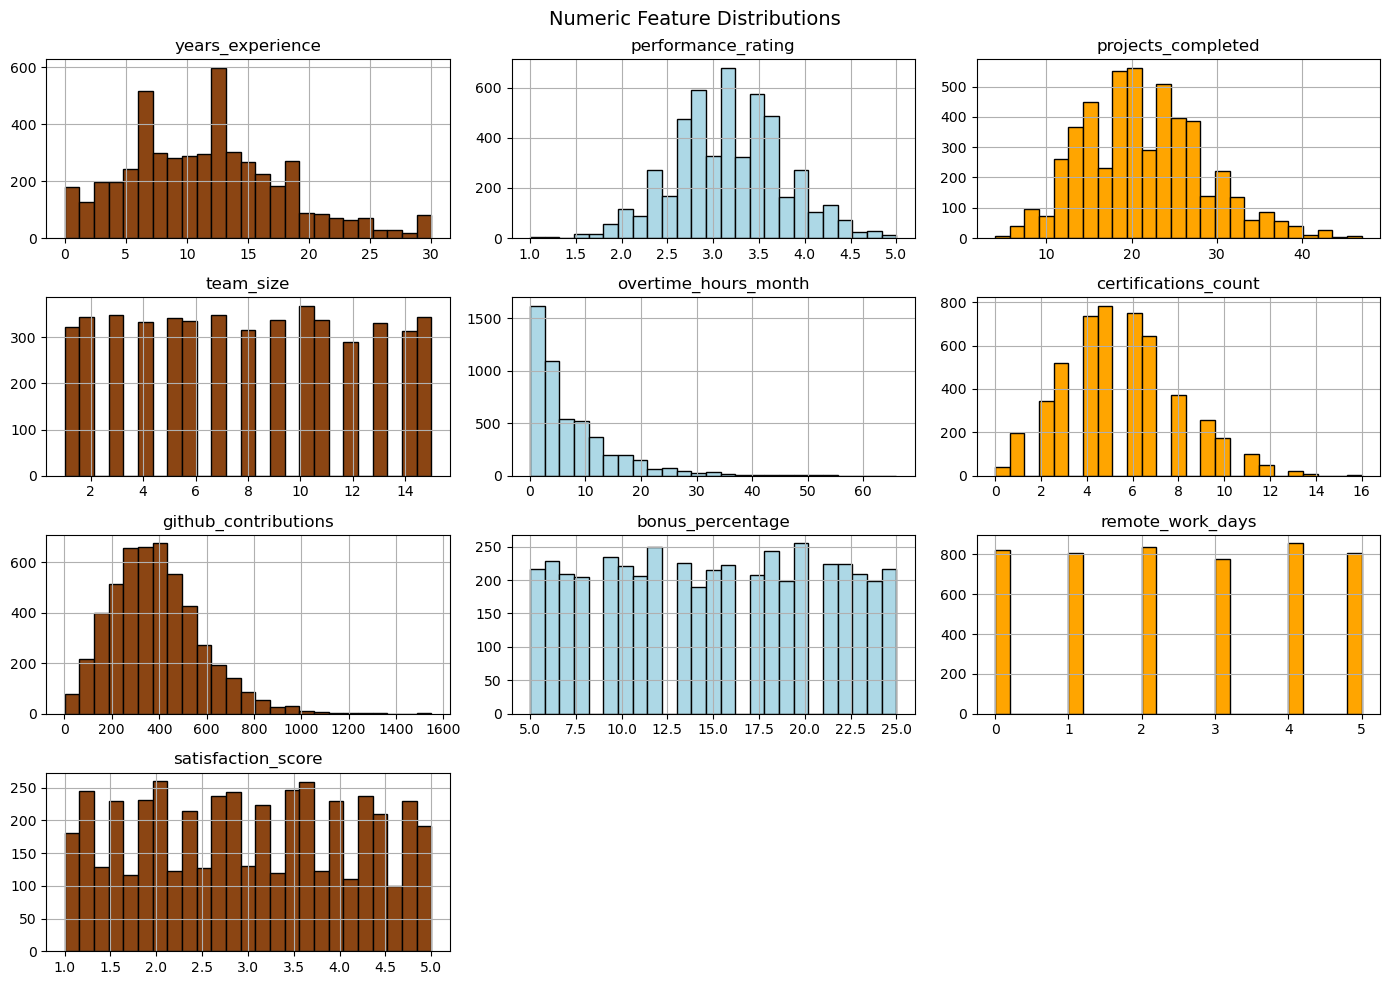

In [24]:

colors = ['saddlebrown', 'lightblue', 'orange']
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if len(num_cols) > 0:
    axes = df[num_cols].hist(figsize=(14,10), bins=25, edgecolor='black')
    axes = axes.flatten()  # flatten the grid of axes
    
    for i, ax in enumerate(axes[:len(num_cols)]):  # match colors to columns
        ax.set_facecolor("white")
        for patch in ax.patches:
            patch.set_facecolor(colors[i % len(colors)])  # cycle palette
    
    plt.suptitle("Numeric Feature Distributions", fontsize=14)
    plt.tight_layout()
    plt.show()


### Boxplots by Target (Numeric Features)

Boxplots show the spread of numeric features grouped by target classes.

Useful for detecting outliers and seeing whether numeric features separate well by target.

BOXPLOTS BY TARGET


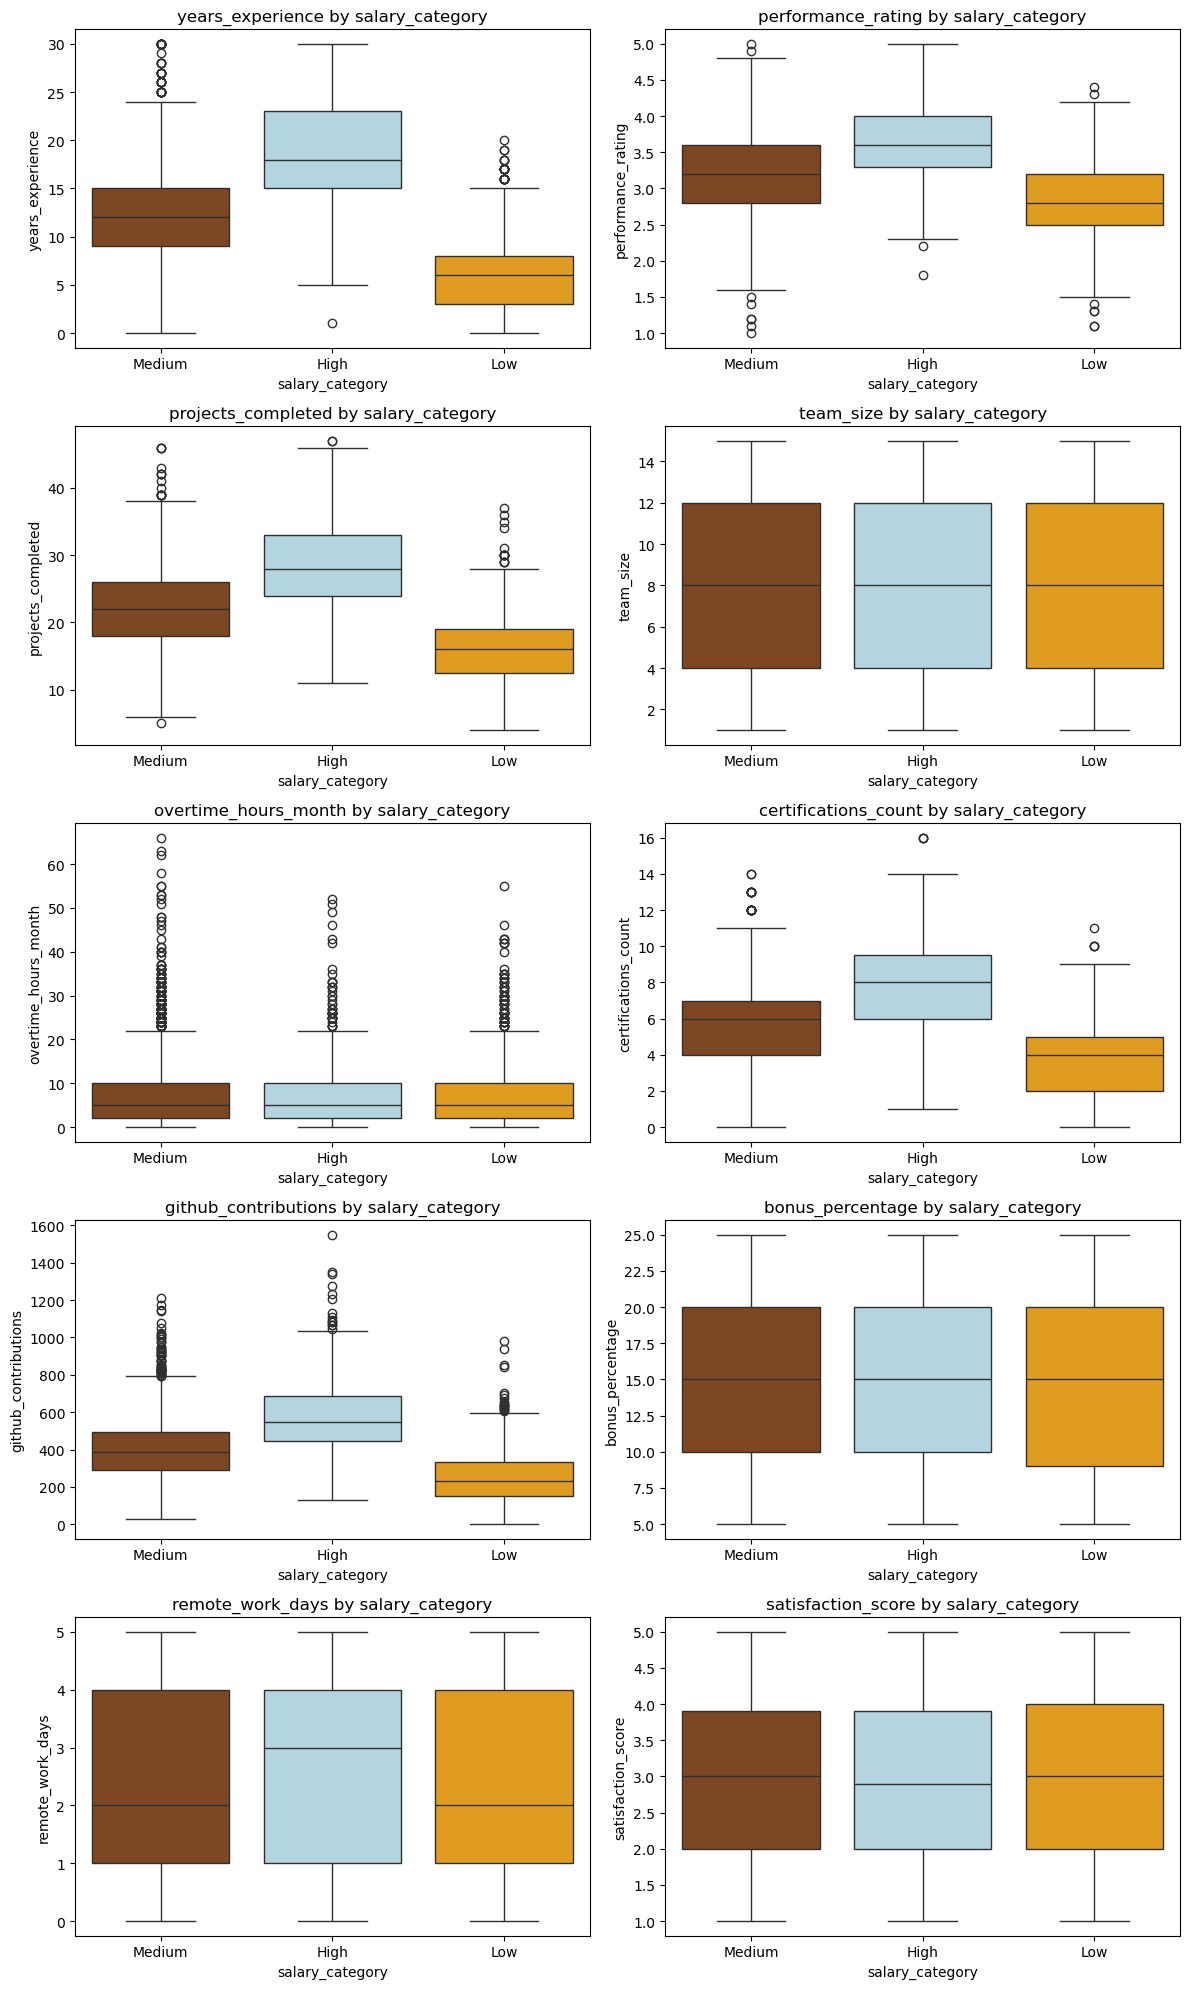

In [25]:

print("BOXPLOTS BY TARGET")

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
palette = ['saddlebrown', 'lightblue', 'orange']  

ncols = 2  
nrows = (len(numeric_cols) + ncols - 1) // ncols  

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4*nrows))
axes = axes.flatten()

for i, c in enumerate(numeric_cols):
    sns.boxplot(
        x=TARGET_COL,
        y=c,
        data=df,
        palette=palette,
        ax=axes[i]
    )
    axes[i].set_title(f"{c} by {TARGET_COL}")
    axes[i].set_xlabel(TARGET_COL)
    axes[i].set_ylabel(c)

# Remove any unused subplots
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### Correlation Heatmap of Numeric Features  

To identify relationships between numeric features, we use a **correlation heatmap**.  

- **High positive/negative correlations** may indicate redundancy between features.  
- Helps in **feature selection** by identifying variables that provide similar information.  
- Useful for detecting potential **multicollinearity**, which can affect some models (Logistic Regression).  


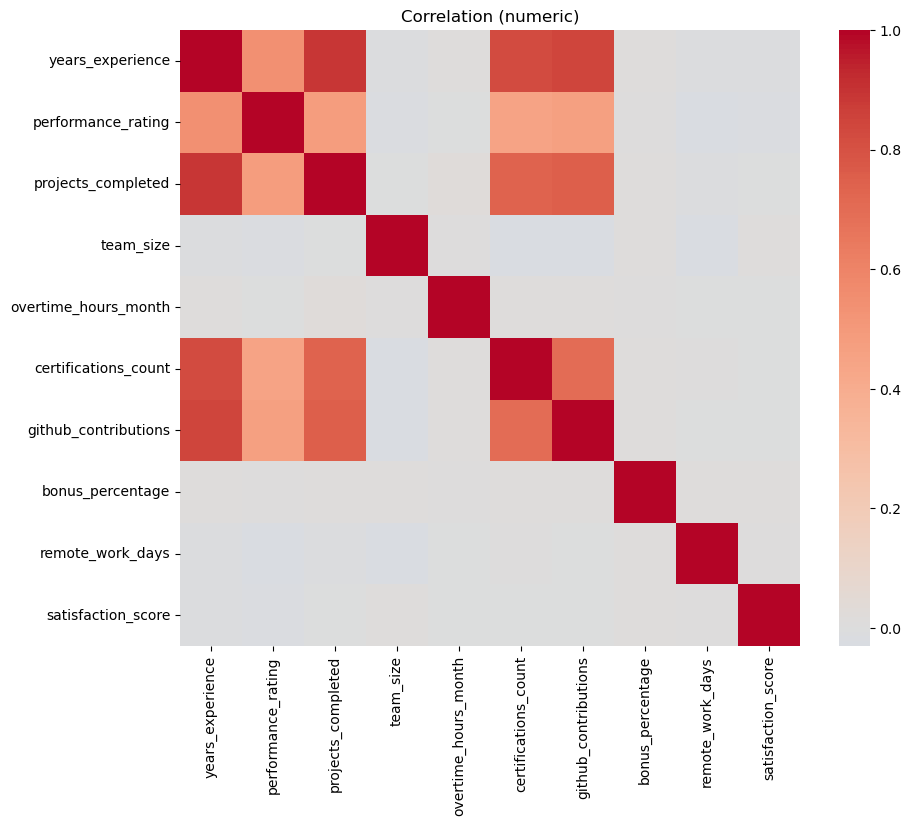

In [26]:
# Correlation heatmap for numeric features
if len(num_cols) > 1:
    plt.figure(figsize=(10,8))
    sns.heatmap(df[num_cols].corr(), cmap='coolwarm', center=0)
    plt.title('Correlation (numeric)')
    plt.show()

### Boxplots of Numeric Features Overview

Boxplots help visualize data distribution and detect outliers.
- Outliers appear as points outside the whiskers.
- Useful for data cleaning and understanding feature spread.

BOXPLOTS TO INSPECT OUTLIERS


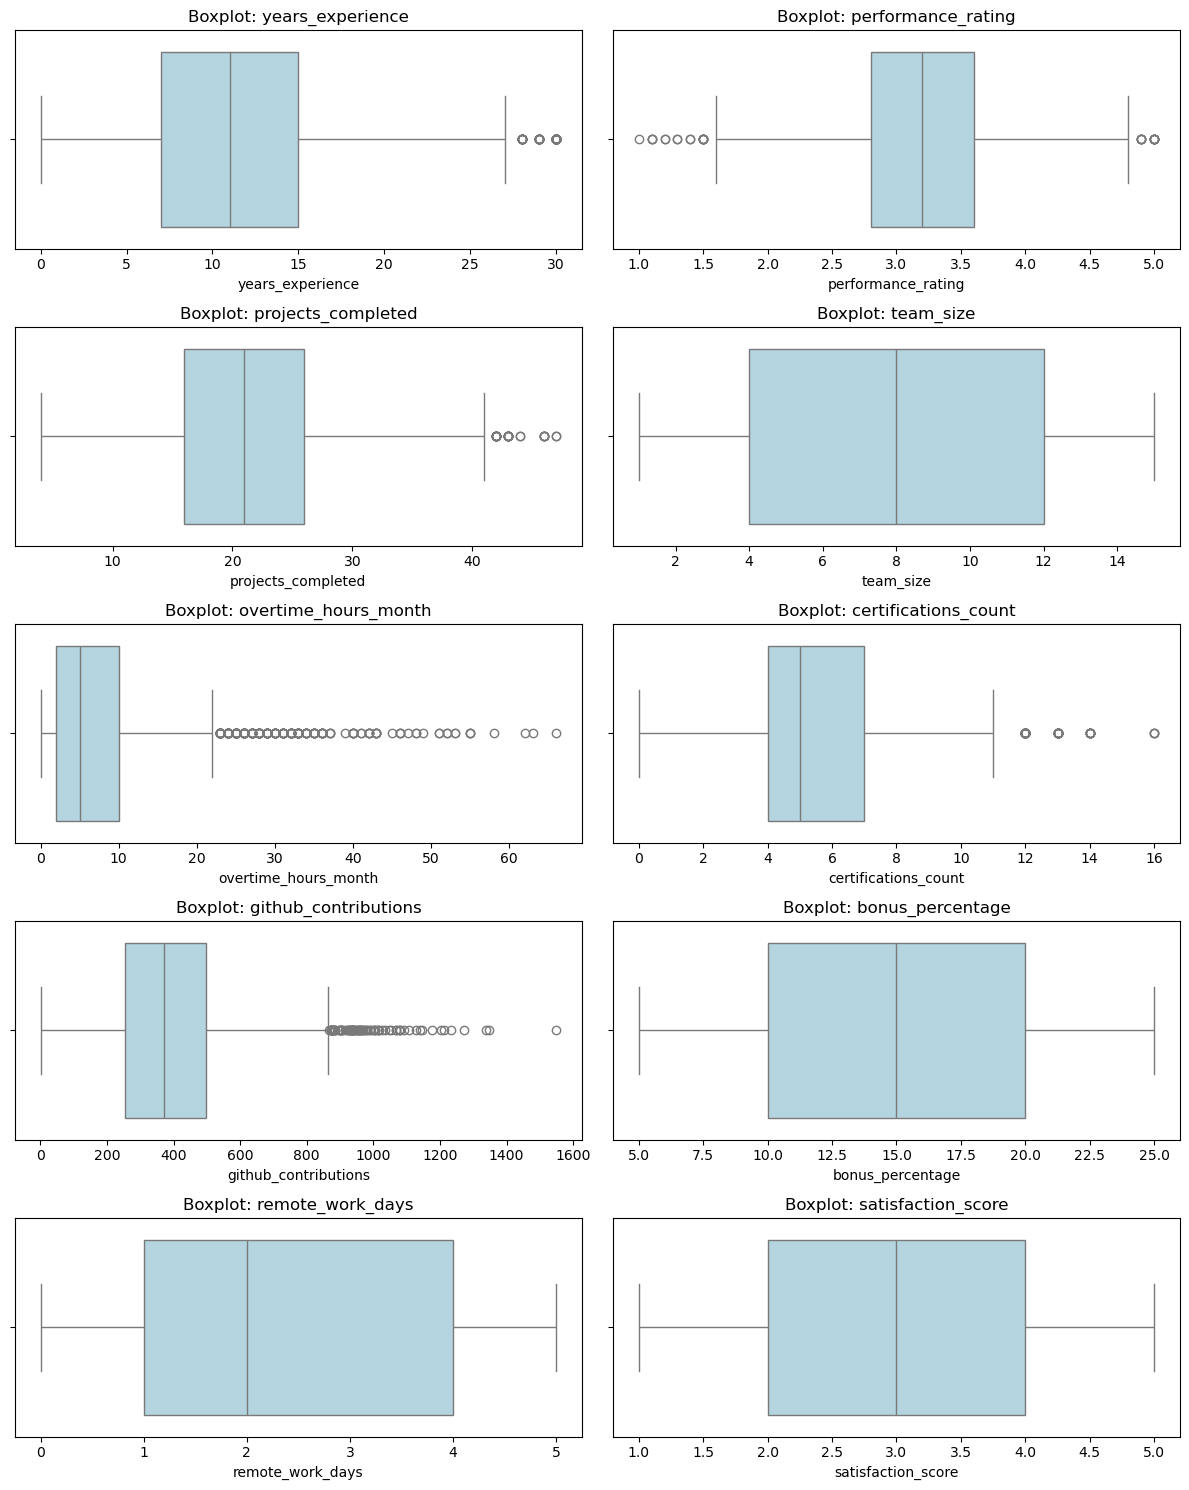

In [27]:
# ----------------------------
# Boxplots to Inspect Outliers (all numeric columns) - Grid Layout
# ----------------------------
print("BOXPLOTS TO INSPECT OUTLIERS")

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

ncols = 2  # number of plots per row
nrows = (len(num_cols) + ncols - 1) // ncols  # compute number of rows

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 3*nrows))
axes = axes.flatten()

for i, c in enumerate(num_cols):
    sns.boxplot(x=df[c], ax=axes[i], color="lightblue")
    axes[i].set_title(f"Boxplot: {c}")
    axes[i].set_xlabel(c)

# Remove unused subplots if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


## Catogorical Features Visualization
### Categorical Distributions by Target

Explore how each categorical feature relates to the target variable.
This is critical for feature importance and model insight.

CATEGORICAL DISTRIBUTIONS


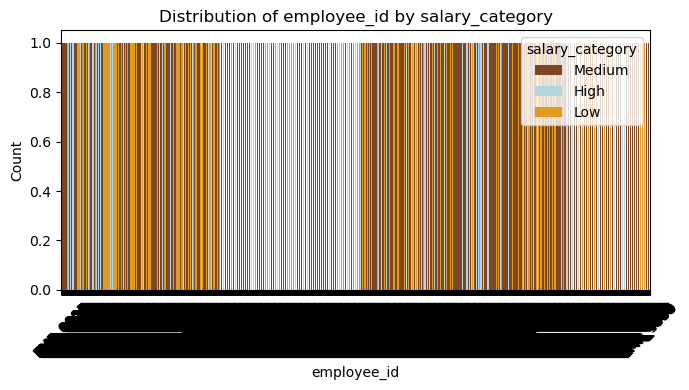

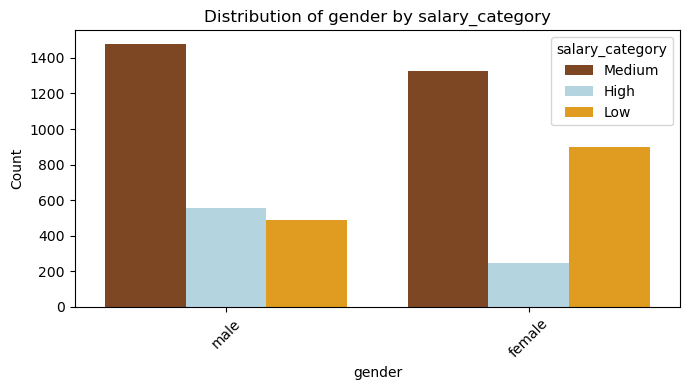

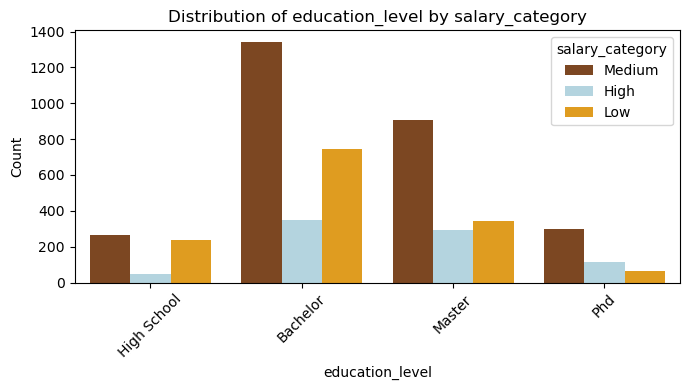

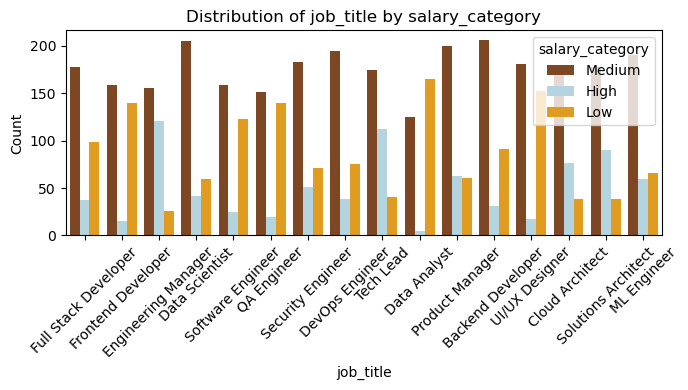

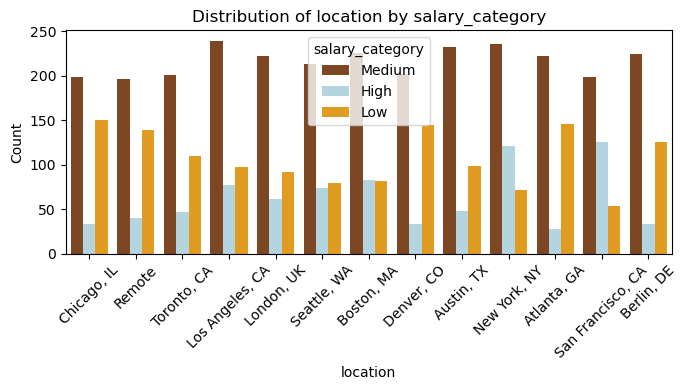

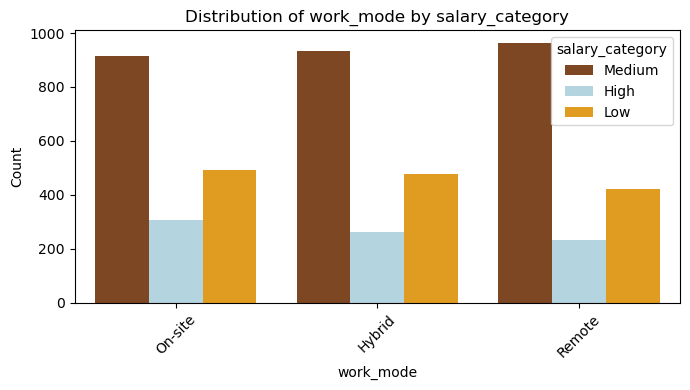

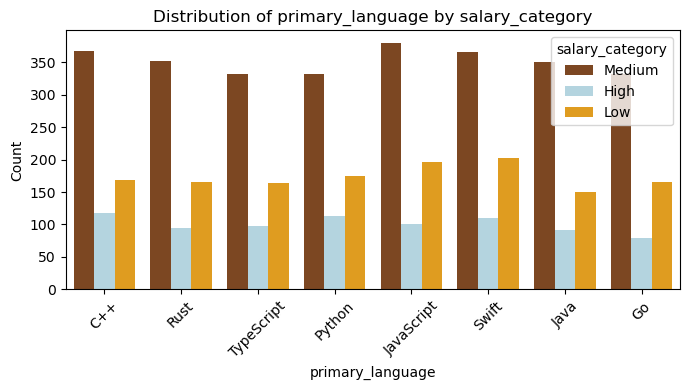

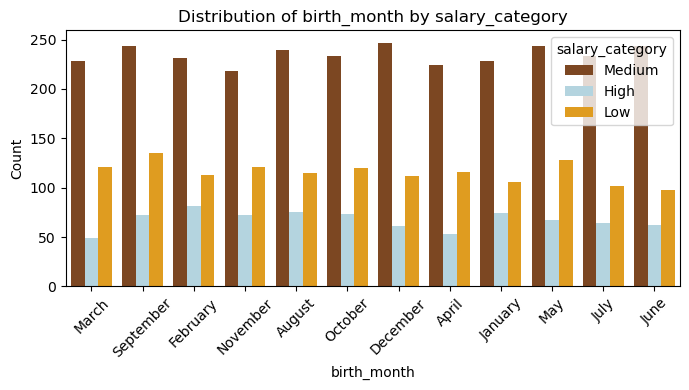

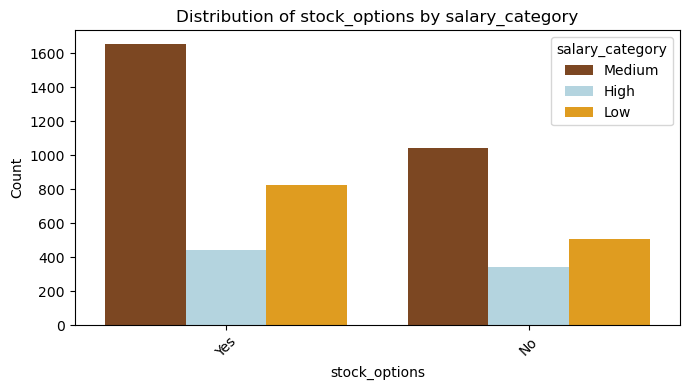

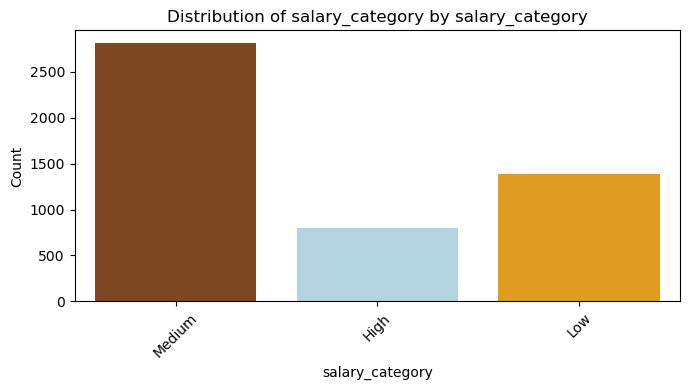

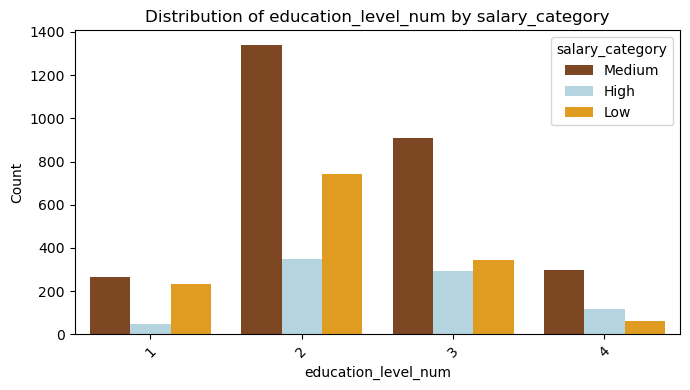

In [28]:
# ----------------------------
# Categorical Distributions by Target
# ----------------------------
#See how categories relate to your prediction target.
print("CATEGORICAL DISTRIBUTIONS")

cat_cols = df.select_dtypes(include=['object','category']).columns.tolist()
palette = ['saddlebrown', 'lightblue', 'orange']

for c in cat_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(x=c, hue=TARGET_COL, data=df,palette=palette)
    plt.xticks(rotation=45)
    plt.title(f"Distribution of {c} by {TARGET_COL}")
    plt.xlabel(c)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()


### Categorical Distributions Overview

Examine all categorical variables, including counts and proportions.
This gives a full overview of dataset balance and category frequencies.

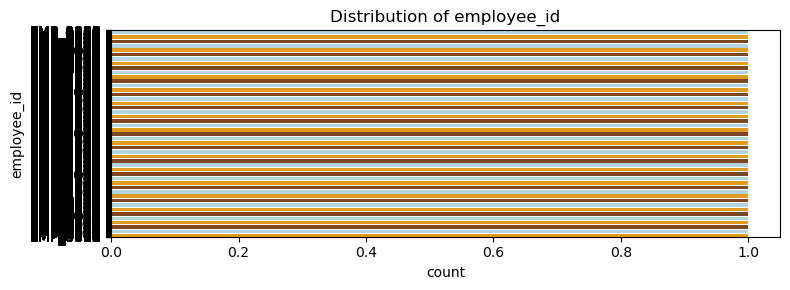


Value counts for employee_id:
employee_id
EMP_5000    1
EMP_0001    1
EMP_0002    1
EMP_0003    1
EMP_0004    1
           ..
EMP_0013    1
EMP_0012    1
EMP_0011    1
EMP_0010    1
EMP_0009    1
Name: count, Length: 5000, dtype: int64

Proportions:
employee_id
EMP_5000    0.0002
EMP_0001    0.0002
EMP_0002    0.0002
EMP_0003    0.0002
EMP_0004    0.0002
             ...  
EMP_0013    0.0002
EMP_0012    0.0002
EMP_0011    0.0002
EMP_0010    0.0002
EMP_0009    0.0002
Name: proportion, Length: 5000, dtype: float64


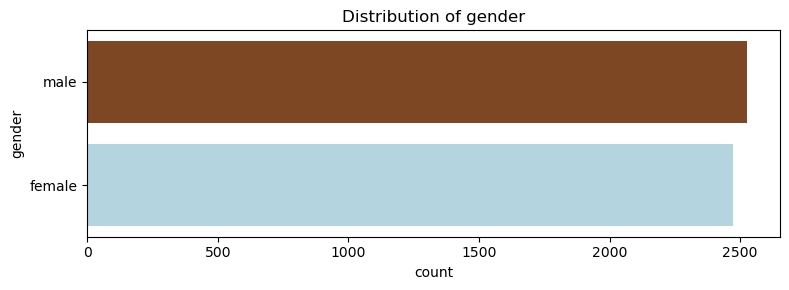


Value counts for gender:
gender
male      2526
female    2474
Name: count, dtype: int64

Proportions:
gender
male      0.5052
female    0.4948
Name: proportion, dtype: float64


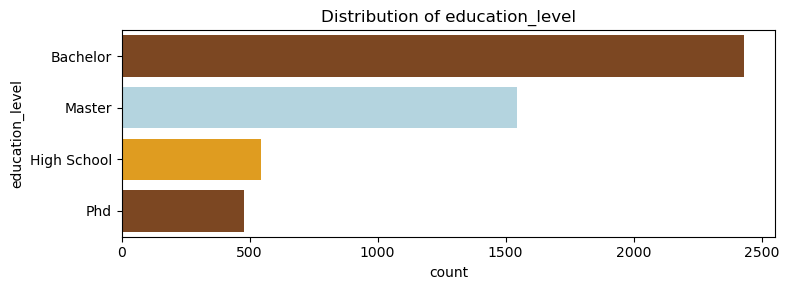


Value counts for education_level:
education_level
Bachelor       2432
Master         1546
High School     545
Phd             477
Name: count, dtype: int64

Proportions:
education_level
Bachelor       0.4864
Master         0.3092
High School    0.1090
Phd            0.0954
Name: proportion, dtype: float64


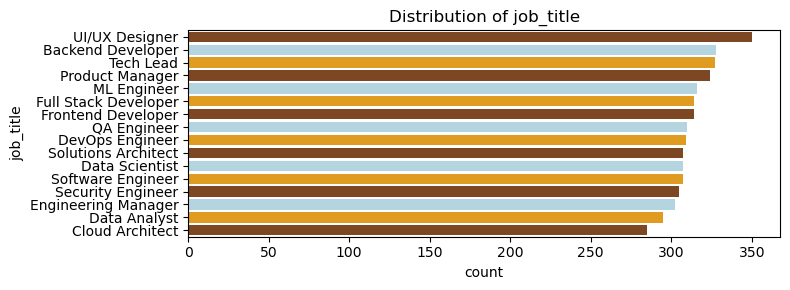


Value counts for job_title:
job_title
UI/UX Designer          350
Backend Developer       328
Tech Lead               327
Product Manager         324
ML Engineer             316
Full Stack Developer    314
Frontend Developer      314
QA Engineer             310
DevOps Engineer         309
Solutions Architect     307
Data Scientist          307
Software Engineer       307
Security Engineer       305
Engineering Manager     302
Data Analyst            295
Cloud Architect         285
Name: count, dtype: int64

Proportions:
job_title
UI/UX Designer          0.0700
Backend Developer       0.0656
Tech Lead               0.0654
Product Manager         0.0648
ML Engineer             0.0632
Full Stack Developer    0.0628
Frontend Developer      0.0628
QA Engineer             0.0620
DevOps Engineer         0.0618
Solutions Architect     0.0614
Data Scientist          0.0614
Software Engineer       0.0614
Security Engineer       0.0610
Engineering Manager     0.0604
Data Analyst            0.059

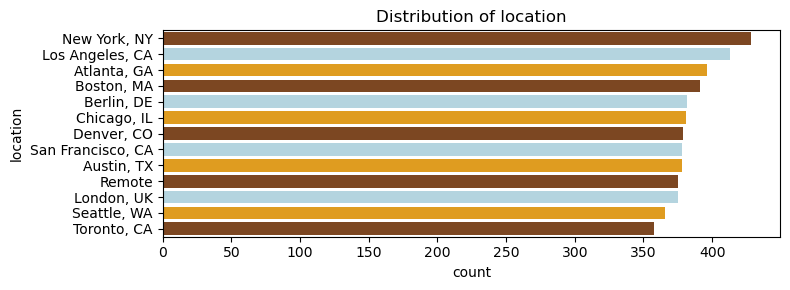


Value counts for location:
location
New York, NY         428
Los Angeles, CA      413
Atlanta, GA          396
Boston, MA           391
Berlin, DE           382
Chicago, IL          381
Denver, CO           379
San Francisco, CA    378
Austin, TX           378
Remote               375
London, UK           375
Seattle, WA          366
Toronto, CA          358
Name: count, dtype: int64

Proportions:
location
New York, NY         0.0856
Los Angeles, CA      0.0826
Atlanta, GA          0.0792
Boston, MA           0.0782
Berlin, DE           0.0764
Chicago, IL          0.0762
Denver, CO           0.0758
San Francisco, CA    0.0756
Austin, TX           0.0756
Remote               0.0750
London, UK           0.0750
Seattle, WA          0.0732
Toronto, CA          0.0716
Name: proportion, dtype: float64


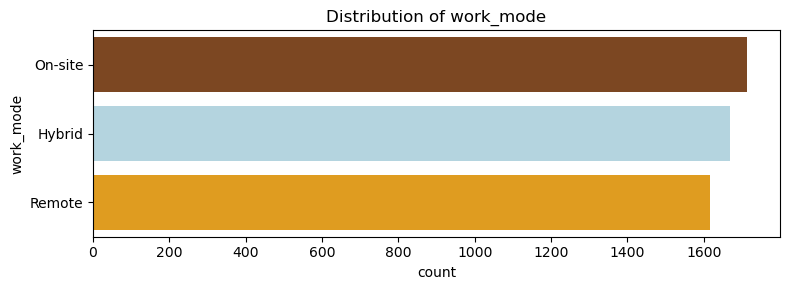


Value counts for work_mode:
work_mode
On-site    1714
Hybrid     1670
Remote     1616
Name: count, dtype: int64

Proportions:
work_mode
On-site    0.3428
Hybrid     0.3340
Remote     0.3232
Name: proportion, dtype: float64


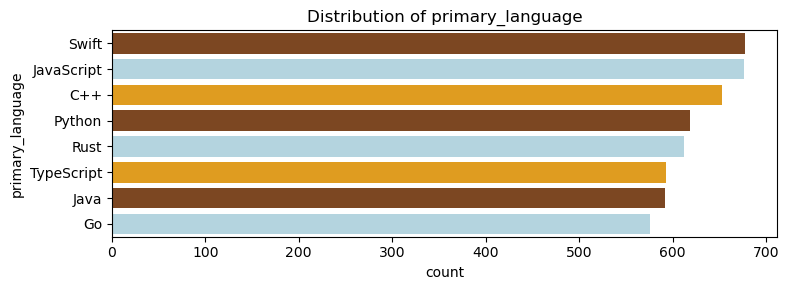


Value counts for primary_language:
primary_language
Swift         678
JavaScript    677
C++           653
Python        619
Rust          612
TypeScript    593
Java          592
Go            576
Name: count, dtype: int64

Proportions:
primary_language
Swift         0.1356
JavaScript    0.1354
C++           0.1306
Python        0.1238
Rust          0.1224
TypeScript    0.1186
Java          0.1184
Go            0.1152
Name: proportion, dtype: float64


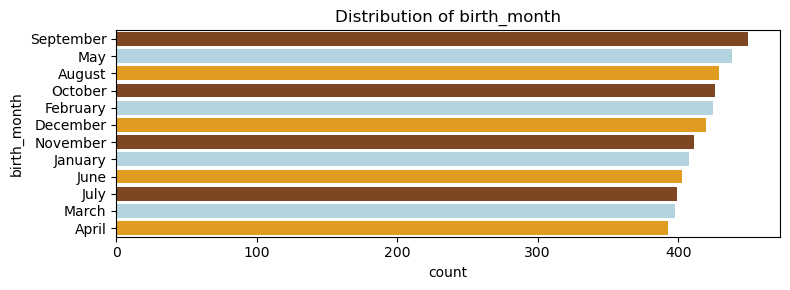


Value counts for birth_month:
birth_month
September    450
May          438
August       429
October      426
February     425
December     420
November     411
January      408
June         403
July         399
March        398
April        393
Name: count, dtype: int64

Proportions:
birth_month
September    0.0900
May          0.0876
August       0.0858
October      0.0852
February     0.0850
December     0.0840
November     0.0822
January      0.0816
June         0.0806
July         0.0798
March        0.0796
April        0.0786
Name: proportion, dtype: float64


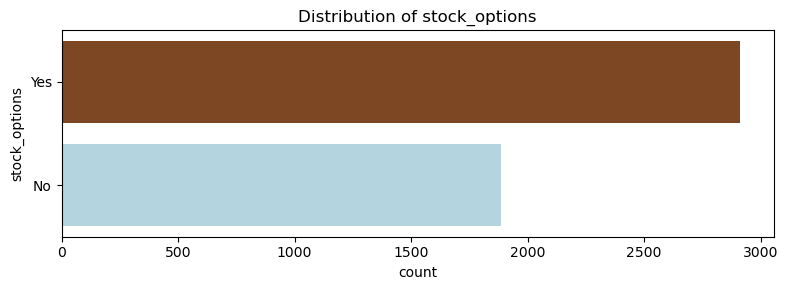


Value counts for stock_options:
stock_options
Yes    2911
No     1888
Name: count, dtype: int64

Proportions:
stock_options
Yes    0.606585
No     0.393415
Name: proportion, dtype: float64


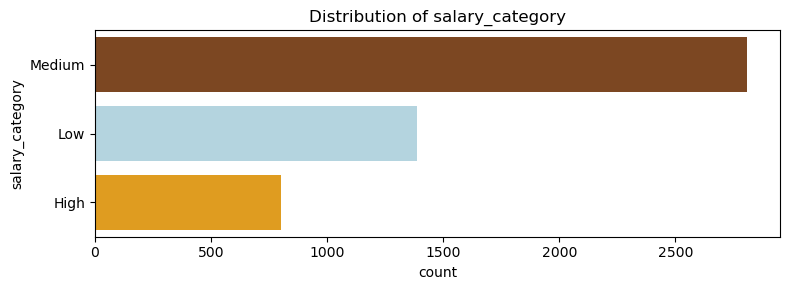


Value counts for salary_category:
salary_category
Medium    2810
Low       1387
High       803
Name: count, dtype: int64

Proportions:
salary_category
Medium    0.5620
Low       0.2774
High      0.1606
Name: proportion, dtype: float64


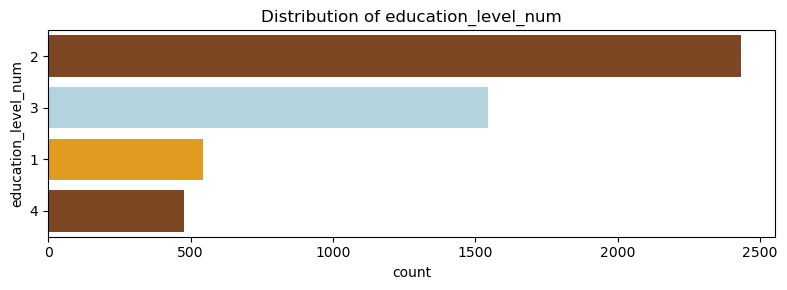


Value counts for education_level_num:
education_level_num
2    2432
3    1546
1     545
4     477
Name: count, dtype: int64

Proportions:
education_level_num
2    0.4864
3    0.3092
1    0.1090
4    0.0954
Name: proportion, dtype: float64


In [29]:
# ----------------------------
# Categorical Distributions (all)
# ----------------------------
#Understand dataset balance / category frequencies.
cat_cols = df.select_dtypes(include=['object','category']).columns.tolist()
palette = ['saddlebrown', 'lightblue', 'orange']

for c in cat_cols:
    plt.figure(figsize=(8, 3))
    sns.countplot(y=c, data=df, order=df[c].value_counts().index, palette=palette)
    plt.title(f"Distribution of {c}")
    plt.tight_layout()
    plt.show()

    # Also print counts & proportions
    print(f"\nValue counts for {c}:")
    print(df[c].value_counts())
    print("\nProportions:")
    print(df[c].value_counts(normalize=True))
    print("="*50)


## 5. Data Preprocessing — Common steps


### Lowercase and Strip String Columns

Purpose: Standardize string/categorical columns to avoid inconsistencies.

Steps performed:
- Convert all entries to string: .astype(str)

- Remove leading/trailing spaces: .str.strip()

- Convert all characters to lowercase: .str.lower()

Helps prevent duplicate categories due to case or spacing differences (e.g., "Male" vs "male" vs " male ").

In [30]:
# Lowercase and strip string columns
for c in df.select_dtypes(include=['object','category']).columns:
    df[c] = df[c].astype(str).str.strip().str.lower()
print('String columns normalized')

String columns normalized


### Impute Simple Missing Values

Fill missing values so that models can process the data.
- Numeric columns: Filled with median value (robust to outliers).
- Categorical column: Filled with most frequent category (mode).

In [31]:
# Impute simple missing values: numeric -> median, categorical -> mode (inplace)
from sklearn.impute import SimpleImputer

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

if num_cols:
    num_imp = SimpleImputer(strategy='median')
    df[num_cols] = num_imp.fit_transform(df[num_cols])

if cat_cols:
    cat_imp = SimpleImputer(strategy='most_frequent')
    df[cat_cols] = cat_imp.fit_transform(df[cat_cols])

print('Missing values after imputation:')
display(df.isnull().sum().sum())

Missing values after imputation:


np.int64(0)

### Define Features and Target

Before modeling, we separate the **input features** (`X`) from the **target variable** (`y`).  

- We remove the numeric version of the education level (`education_level_num`) which is created for ordinal blox-plot visualization above.  
  **Reason:**  
  - The ordinal feature `education_level` may already be properly encoded (as categories or using an ordinal encoder).  
  - Keeping `education_level_num` would **duplicate information**, which can lead to redundancy and may affect model performance.  

- `FEATURE_COLS` contains all columns **except the target column**.  
- `len(FEATURE_COLS)` shows the total number of input features available for modeling.  
- Displaying `FEATURE_COLS[:20]` provides a **quick sample of features** being used.


In [32]:
# Remove numeric education level column
if 'education_level_num' in df.columns:
    df = df.drop(columns=['education_level_num'])

# Check
print("Columns after dropping education_level_num:")
print(df.columns)


# Define features and target
FEATURE_COLS = [c for c in df.columns if c != TARGET_COL]
print('Number of features:', len(FEATURE_COLS))
print('Sample features:', FEATURE_COLS[:20])

Columns after dropping education_level_num:
Index(['employee_id', 'years_experience', 'gender', 'education_level',
       'job_title', 'location', 'work_mode', 'primary_language',
       'performance_rating', 'projects_completed', 'team_size',
       'overtime_hours_month', 'certifications_count', 'github_contributions',
       'birth_month', 'bonus_percentage', 'stock_options', 'remote_work_days',
       'satisfaction_score', 'salary_category'],
      dtype='object')
Number of features: 19
Sample features: ['employee_id', 'years_experience', 'gender', 'education_level', 'job_title', 'location', 'work_mode', 'primary_language', 'performance_rating', 'projects_completed', 'team_size', 'overtime_hours_month', 'certifications_count', 'github_contributions', 'birth_month', 'bonus_percentage', 'stock_options', 'remote_work_days', 'satisfaction_score']


## Dataset Plans: A, B, and C
After the common preprocessing steps (lowercasing strings, imputing missing values), we create three dataset variations for experimentation:

### Plan A — Keep All Data including Outliers

This plan keeps all rows but uses the common preprocessing above.
Serves as a baseline dataset including all observations and features.

In [33]:
# Plan A: keep outliers (just use df as-is after common preprocessing)
df_A = df.copy()
# Ensure target exists
assert TARGET_COL in df_A.columns, f"Target column {TARGET_COL} not found"
print('Plan A dataset shape:', df_A.shape)
display(df_A.head())

Plan A dataset shape: (5000, 20)


,employee_id,years_experience,gender,education_level,job_title,location,work_mode,primary_language,performance_rating,projects_completed,team_size,overtime_hours_month,certifications_count,github_contributions,birth_month,bonus_percentage,stock_options,remote_work_days,satisfaction_score,salary_category
0,emp_0001,11.0,male,phd,full stack developer,"chicago, il",on-site,c++,3.2,19.0,9.0,15.0,6.0,370.0,march,15.0,yes,2.0,3.7,medium
1,emp_0002,20.0,male,bachelor,frontend developer,remote,hybrid,c++,4.1,30.0,13.0,7.0,8.0,523.0,march,13.0,yes,3.0,3.1,medium
2,emp_0003,21.0,male,bachelor,engineering manager,"toronto, ca",remote,rust,3.9,32.0,10.0,1.0,9.0,555.0,september,10.0,no,3.0,4.9,high
3,emp_0004,7.0,female,phd,data scientist,"los angeles, ca",remote,typescript,3.3,17.0,4.0,0.0,4.0,253.0,february,24.0,no,1.0,3.0,medium
4,emp_0005,10.0,female,bachelor,engineering manager,"london, uk",remote,python,3.6,15.0,3.0,0.0,4.0,255.0,november,15.0,yes,5.0,2.8,high


### Plan B — Remove Outliers 

Remove outlier rows using the **Interquartile Range (IQR)** method on numeric features.

- For each numeric column:
  - Compute Q1 (25th percentile) and Q3 (75th percentile).
  - Calculate IQR = Q3 − Q1.
  - Keep rows where values fall within [Q1 − 1.5×IQR, Q3 + 1.5×IQR].
  
**Purpose:**  
- Reduce extreme values that may distort model training.  
- Ensure more robust and stable model performance by limiting the influence of outliers.


In [34]:
# Plan B: remove outliers by z-score threshold
# Make a copy of original dataset
df_B = df_A.copy()

# Select numeric columns
num_cols_B = df_B.select_dtypes(include=['float64', 'int64']).columns

# Remove outliers using IQR
for col in num_cols_B:
    Q1 = df_B[col].quantile(0.25)
    Q3 = df_B[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_B = df_B[(df_B[col] >= lower_bound) & (df_B[col] <= upper_bound)]

# Reset index
df_B = df_B.reset_index(drop=True)

# Display results
print('Plan B dataset shape:', df_B.shape)
display(df_B.head())

Plan B dataset shape: (4451, 20)


,employee_id,years_experience,gender,education_level,job_title,location,work_mode,primary_language,performance_rating,projects_completed,team_size,overtime_hours_month,certifications_count,github_contributions,birth_month,bonus_percentage,stock_options,remote_work_days,satisfaction_score,salary_category
0,emp_0001,11.0,male,phd,full stack developer,"chicago, il",on-site,c++,3.2,19.0,9.0,15.0,6.0,370.0,march,15.0,yes,2.0,3.7,medium
1,emp_0002,20.0,male,bachelor,frontend developer,remote,hybrid,c++,4.1,30.0,13.0,7.0,8.0,523.0,march,13.0,yes,3.0,3.1,medium
2,emp_0003,21.0,male,bachelor,engineering manager,"toronto, ca",remote,rust,3.9,32.0,10.0,1.0,9.0,555.0,september,10.0,no,3.0,4.9,high
3,emp_0004,7.0,female,phd,data scientist,"los angeles, ca",remote,typescript,3.3,17.0,4.0,0.0,4.0,253.0,february,24.0,no,1.0,3.0,medium
4,emp_0005,10.0,female,bachelor,engineering manager,"london, uk",remote,python,3.6,15.0,3.0,0.0,4.0,255.0,november,15.0,yes,5.0,2.8,high


### Plan C — Reduced Specific Features and Outliers

Drop certain columns deemed irrelevant or sensitive.

Based on feature analysis, we remove features that are unlikely to help prediction:
- employee_id: A unique identifier with no predictive value; including it could lead to overfitting or memorization.
- birth_month: Not directly relevant for the target; may introduce noise or spurious correlations.


In [35]:
# Plan C: drop specific features + remove outliers

# Step 1: Drop specific features
drop_list = ['employee_id', 'birth_month']
drop_list = [c for c in drop_list if c in df_A.columns]
df_C = df_A.drop(columns=drop_list, errors='ignore').reset_index(drop=True)

# Step 2: Remove outliers using IQR for all numeric columns
num_cols = df_C.select_dtypes(include=['float64', 'int64']).columns

for col in num_cols:
    Q1 = df_C[col].quantile(0.25)
    Q3 = df_C[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_C = df_C[(df_C[col] >= lower_bound) & (df_C[col] <= upper_bound)]

df_C = df_C.reset_index(drop=True)

print('Plan C dataset shape:', df_C.shape)
print('Dropped columns:', drop_list)
display(df_C.head())


Plan C dataset shape: (4451, 18)
Dropped columns: ['employee_id', 'birth_month']


,years_experience,gender,education_level,job_title,location,work_mode,primary_language,performance_rating,projects_completed,team_size,overtime_hours_month,certifications_count,github_contributions,bonus_percentage,stock_options,remote_work_days,satisfaction_score,salary_category
0,11.0,male,phd,full stack developer,"chicago, il",on-site,c++,3.2,19.0,9.0,15.0,6.0,370.0,15.0,yes,2.0,3.7,medium
1,20.0,male,bachelor,frontend developer,remote,hybrid,c++,4.1,30.0,13.0,7.0,8.0,523.0,13.0,yes,3.0,3.1,medium
2,21.0,male,bachelor,engineering manager,"toronto, ca",remote,rust,3.9,32.0,10.0,1.0,9.0,555.0,10.0,no,3.0,4.9,high
3,7.0,female,phd,data scientist,"los angeles, ca",remote,typescript,3.3,17.0,4.0,0.0,4.0,253.0,24.0,no,1.0,3.0,medium
4,10.0,female,bachelor,engineering manager,"london, uk",remote,python,3.6,15.0,3.0,0.0,4.0,255.0,15.0,yes,5.0,2.8,high


## 6. Train / Validation / Test Splits (per plan)

Create stratified splits for each plan so comparisons are fair.

- Training set: 80% of data
- Validation set: 10%
- Test set: 10%

Stratification ensures class distributions remain consistent across splits.

### Plan A

Use the dataset as-is after common preprocessing (keep all outliers).


In [36]:
# Helper inline splitting for Plan A
from sklearn.model_selection import train_test_split

X_A = df_A.drop(columns=[TARGET_COL])
y_A = df_A[TARGET_COL]
X_train_A, X_temp_A, y_train_A, y_temp_A = train_test_split(X_A, y_A, test_size=0.2, stratify=y_A, random_state=42)
X_val_A, X_test_A, y_val_A, y_test_A = train_test_split(X_temp_A, y_temp_A, test_size=0.5, stratify=y_temp_A, random_state=42)
print('Plan A: train/val/test shapes:', X_train_A.shape, X_val_A.shape, X_test_A.shape)

Plan A: train/val/test shapes: (4000, 19) (500, 19) (500, 19)


### Plan B

Remove outliers using IQR.

In [37]:
# Splits for Plan B
X_B = df_B.drop(columns=[TARGET_COL])
y_B = df_B[TARGET_COL] 
X_train_B, X_temp_B, y_train_B, y_temp_B = train_test_split(X_B, y_B, test_size=0.2, stratify=y_B, random_state=42)
X_val_B, X_test_B, y_val_B, y_test_B = train_test_split(X_temp_B, y_temp_B, test_size=0.5, stratify=y_temp_B, random_state=42)
print('Plan B: train/val/test shapes:', X_train_B.shape, X_val_B.shape, X_test_B.shape)

Plan B: train/val/test shapes: (3560, 19) (445, 19) (446, 19)


### Plan C

Drop features identified as unnecessary or potentially misleading (employee_id, birth_month).

In [38]:
# Splits for Plan C
X_C = df_C.drop(columns=[TARGET_COL])
y_C = df_C[TARGET_COL]
X_train_C, X_temp_C, y_train_C, y_temp_C = train_test_split(X_C, y_C, test_size=0.2, stratify=y_C, random_state=42)
X_val_C, X_test_C, y_val_C, y_test_C = train_test_split(X_temp_C, y_temp_C, test_size=0.5, stratify=y_temp_C, random_state=42)
print('Plan C: train/val/test shapes:', X_train_C.shape, X_val_C.shape, X_test_C.shape)

Plan C: train/val/test shapes: (3560, 17) (445, 17) (446, 17)


### Splits Summary

The summary table and stacked bar chart show how the dataset was split for **each plan (A, B, C)**:  

- **Rows before modification:** Total number of samples in each dataset before any preprocessing or filtering.  
- **Train samples:** Number of samples used for model training.  
- **Validation samples:** Number of samples used for hyperparameter tuning and model selection.  
- **Test samples:** Number of samples reserved for final model evaluation.  

The **stacked bar chart** visually represents the distribution of samples across train, validation, and test sets for each plan:  
- Orange → Train set  
- Brown → Validation set  
- Light blue → Test set  

This overview helps verify that:  
- The splits are consistent and proportional across plans.  
- No plan has too few samples in any split, which could affect model performance or evaluation reliability.

,Plan,Rows before modification,Train samples,Validation samples,Test samples
0,A,5000,4000,500,500
1,B,4451,3560,445,446
2,C,4451,3560,445,446


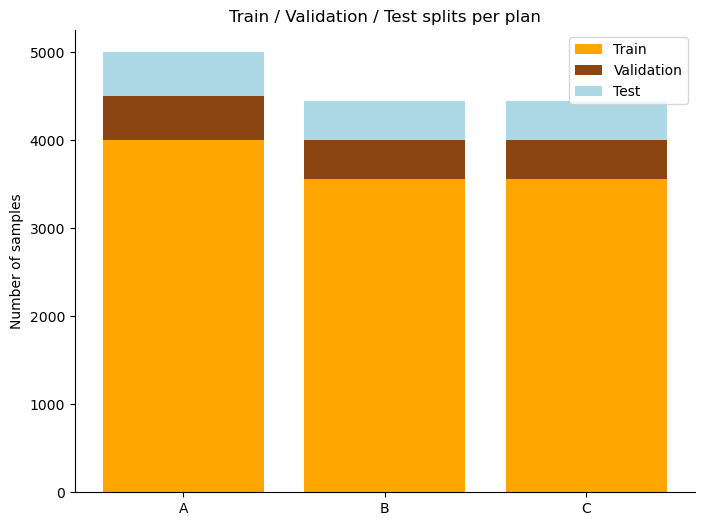

In [39]:
# Prepare summary table
splits_summary = {
    "Plan": ["A", "B", "C"],
    "Rows before modification": [df_A.shape[0], df_B.shape[0], df_C.shape[0]],
    "Train samples": [X_train_A.shape[0], X_train_B.shape[0], X_train_C.shape[0]],
    "Validation samples": [X_val_A.shape[0], X_val_B.shape[0], X_val_C.shape[0]],
    "Test samples": [X_test_A.shape[0], X_test_B.shape[0], X_test_C.shape[0]]
}

df_splits_summary = pd.DataFrame(splits_summary)
display(df_splits_summary)

colors = ['orange', 'saddlebrown', 'lightblue']  

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(8,6))

plans = df_splits_summary['Plan']

train = df_splits_summary['Train samples']
val = df_splits_summary['Validation samples']
test = df_splits_summary['Test samples']

ax.bar(plans, train, label='Train', color=colors[0])
ax.bar(plans, val, bottom=train, label='Validation', color=colors[1])
ax.bar(plans, test, bottom=train+val, label='Test', color=colors[2])

ax.set_ylabel('Number of samples')
ax.set_title('Train / Validation / Test splits per plan')
ax.legend()
sns.despine()
plt.show()


## 7. Models — define (8 models)

In this step, we define the set of machine learning models to be evaluated for all three plans (A, B, C). We aim to cover a diverse set of algorithms to capture different patterns in the data. 

Models used:
- `Logistic Regression`
- `Random Forest`
- `Gradient Boosting`
- `XGBoost`
- `Support Vector Machine (SVM)`
- `k-Nearest Neighbor (k-NN)`
- `Naive Bayes`
- `SGD Classifier`

| Model | Type | Reason for Inclusion |
| --- | --- | --- |
| Logistic Regression | Linear | A simple and interpretable baseline for classification; works well with numeric and standardized features. |
| Random Forest | Tree-based Ensemble | Captures non-linear relationships, robust to outliers, and handles both numeric and categorical data. |
| Gradient Boosting | Ensemble | Sequentially improves weak learners, often achieving high accuracy on structured tabular data. |
| XGBoost | Ensemble | Optimized implementation of gradient boosting; faster and more regularized to reduce overfitting. |
| Support Vector Machine (SVM) | Linear / Non-linear | Effective in high-dimensional spaces; can capture complex boundaries with kernels. |
| k-Nearest Neighbor (k-NN) | Instance-based | Simple, non-parametric method based on proximity; useful as a benchmark for local patterns. |
| Naive Bayes | Probabilistic | Fast, handles categorical features well, and provides probabilistic outputs; good baseline. |
| SGD Classifier | Linear / Optimization-based | Efficient for large-scale datasets; supports different loss functions |


In [40]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': (xgb.XGBClassifier(eval_metric='mlogloss', use_label_encoder=False, random_state=42) if xgb is not None else None),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'k-Nearest Neighbor': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'SGD Classifier': SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)
}
# remove None models (if xgboost absent)
models = {k:v for k,v in models.items() if v is not None}
models

{'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=2000),
 'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=200,
                        random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric='mlogloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=None, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=None, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=N

### Train Models — Plan A (Baseline)

In **Plan A**, we train all selected models on the dataset **without removing outliers or dropping any columns** to establish a baseline for comparison with Plan B and Plan C.

**Steps:**

1. **Define numeric and categorical columns**  
   - Numeric features (`num_cols_A`) are standardized using `StandardScaler`.  
   - Categorical features (`cat_cols_A`) are one-hot encoded with `OneHotEncoder` (`handle_unknown='ignore'`).

2. **Label encoding for XGBoost**  
   - XGBoost requires numeric labels for multi-class classification (`LabelEncoder`).  
   - Other models use the original labels.

3. **Pipeline setup**  
   - `ColumnTransformer` applies preprocessing to the correct column types.  
   - `Pipeline` combines preprocessing and model fitting for clean, reproducible workflows.

4. **Model training and evaluation**  
   - Each model is trained on the training set and evaluated on validation and test sets.  
   - Metrics computed: **accuracy** and **weighted F1-score**.  
   - Errors during training are captured for troubleshooting.

5. **Store results**  
   - Results for all models are saved in `df_results_A`.  
   - Trained pipelines are saved in `trained_A` for reuse or further analysis.

This approach allows quick comparison of model performance under **baseline preprocessing**.


In [41]:
# Identify numeric and categorical columns
num_cols_A = X_train_A.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_A = [c for c in X_train_A.columns if c not in num_cols_A]

# LabelEncoder for XGBoost target
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train_A)
y_val_enc   = le.transform(y_val_A)
y_test_enc  = le.transform(y_test_A)

results_A = []
trained_A = {}

for name, model in models.items():
    print('\n=== Model:', name, '(Plan A) ===')
    
    # Set up preprocessing
    transformers = []
    if num_cols_A:
        transformers.append(('num', StandardScaler(), num_cols_A))
    if cat_cols_A:
        transformers.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_A))

    preproc = ColumnTransformer(transformers=transformers, remainder='drop')
    pipe = Pipeline(steps=[('preproc', preproc), ('model', model)])
    
    try:
        # Use encoded labels for XGBoost, normal labels for other models
        y_cv = y_train_enc if name == "XGBoost" else y_train_A
        
        # Cross-validation
        cv_scores = cross_val_score(pipe, X_train_A, y_cv, cv=5, scoring='accuracy')
        cv_mean = np.mean(cv_scores)
        cv_std = np.std(cv_scores)
        
        # Fit model
        y_fit = y_train_enc if name == "XGBoost" else y_train_A
        pipe.fit(X_train_A, y_fit)
        
        # Predict
        if name == "XGBoost":
            y_val_pred = le.inverse_transform(pipe.predict(X_val_A))
            y_test_pred = le.inverse_transform(pipe.predict(X_test_A))
        else:
            y_val_pred = pipe.predict(X_val_A)
            y_test_pred = pipe.predict(X_test_A)
        
        # Save results
        res = {
            'plan': 'A',
            'model': name,
            'cv_mean_acc': cv_mean,
            'cv_std': cv_std,
            'val_acc': accuracy_score(y_val_A, y_val_pred),
            'test_acc': accuracy_score(y_test_A, y_test_pred),
            'val_f1': f1_score(y_val_A, y_val_pred, average='weighted'),
            'test_f1': f1_score(y_test_A, y_test_pred, average='weighted')
        }
        print(f"CV Mean Acc: {cv_mean:.3f} (+/- {cv_std:.3f}) | Val acc: {res['val_acc']:.3f} | Test acc: {res['test_acc']:.3f}")
        
    except Exception as e:
        res = {'plan':'A','model':name,'error':str(e)}
        print('Error:', e)
    
    results_A.append(res)
    trained_A[name] = pipe

# Convert results to DataFrame
df_results_A = pd.DataFrame(results_A)
display(df_results_A.sort_values('cv_mean_acc', ascending=False).reset_index(drop=True))


=== Model: Logistic Regression (Plan A) ===
CV Mean Acc: 0.842 (+/- 0.017) | Val acc: 0.832 | Test acc: 0.804

=== Model: Random Forest (Plan A) ===
CV Mean Acc: 0.758 (+/- 0.014) | Val acc: 0.748 | Test acc: 0.756

=== Model: Gradient Boosting (Plan A) ===
CV Mean Acc: 0.807 (+/- 0.009) | Val acc: 0.812 | Test acc: 0.792

=== Model: XGBoost (Plan A) ===
CV Mean Acc: 0.814 (+/- 0.022) | Val acc: 0.804 | Test acc: 0.790

=== Model: Support Vector Machine (Plan A) ===
CV Mean Acc: 0.824 (+/- 0.011) | Val acc: 0.804 | Test acc: 0.776

=== Model: k-Nearest Neighbor (Plan A) ===
CV Mean Acc: 0.673 (+/- 0.011) | Val acc: 0.632 | Test acc: 0.654

=== Model: Naive Bayes (Plan A) ===
CV Mean Acc: 0.161 (+/- 0.001) | Val acc: 0.160 | Test acc: 0.162

=== Model: SGD Classifier (Plan A) ===
CV Mean Acc: 0.835 (+/- 0.012) | Val acc: 0.804 | Test acc: 0.798


,plan,model,cv_mean_acc,cv_std,val_acc,test_acc,val_f1,test_f1
0,A,Logistic Regression,0.84200,0.017277,0.832,0.804,0.832570,0.804628
1,A,SGD Classifier,0.83550,0.011927,0.804,0.798,0.803406,0.797037
2,A,Support Vector Machine,0.82400,0.010735,0.804,0.776,0.801269,0.772279
3,A,XGBoost,0.81350,0.021555,0.804,0.790,0.801286,0.787746
4,A,Gradient Boosting,0.80700,0.009274,0.812,0.792,0.808976,0.788534
5,A,Random Forest,0.75825,0.014265,0.748,0.756,0.729410,0.739140
6,A,k-Nearest Neighbor,0.67325,0.010741,0.632,0.654,0.625377,0.648309
7,A,Naive Bayes,0.16050,0.000612,0.160,0.162,0.044138,0.045170


### Train Models — Plan B (Outlier Removal)

In **Plan B**, we remove outliers from the dataset using the **IQR method**.  
This helps prevent extreme values from skewing the model and potentially improves stability and predictive performance.

**Steps:**

1. **Preprocessing columns**  
   - Numeric features are standardized with `StandardScaler`.  
   - Categorical features are one-hot encoded with `OneHotEncoder` (`handle_unknown='ignore'`).

2. **Handling XGBoost target**  
   - XGBoost requires numeric labels, so we encode the target only for XGBoost using `LabelEncoder`.  
   - Other models use the original target values.

3. **Pipeline construction**  
   - `ColumnTransformer` applies preprocessing to the correct column types.  
   - `Pipeline` chains preprocessing and model fitting for consistent transformations across train, validation, and test sets.

4. **Model training and evaluation**  
   - Each model is trained on the **outlier-cleaned training set**.  
   - Predictions are made on validation and test sets.  
   - Metrics computed: **accuracy** and **weighted F1-score**.  
   - Errors during training are captured for troubleshooting.

5. **Store results**  
   - Results for all models are saved in `df_results_B`.  
   - Trained pipelines are saved in `trained_B` for reuse or further analysis.

This setup allows us to **compare performance with Plan A** and assess the impact of outlier removal on model metrics.


In [42]:
num_cols_B = X_train_B.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_B = [c for c in X_train_B.columns if c not in num_cols_B]

# Encode y for XGBoost
y_train_B_enc = le.fit_transform(y_train_B)
y_val_B_enc   = le.transform(y_val_B)
y_test_B_enc  = le.transform(y_test_B)

results_B = []
trained_B = {}

for name, model in models.items():
    print('\n=== Model:', name, '(Plan B) ===')
    
    transformers = []
    if num_cols_B:
        transformers.append(('num', StandardScaler(), num_cols_B))
    if cat_cols_B:
        transformers.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_B))

    preproc = ColumnTransformer(transformers=transformers, remainder='drop')
    pipe = Pipeline(steps=[('preproc', preproc), ('model', model)])
    
    try:
        # Use encoded labels for XGBoost in CV
        y_cv = y_train_B_enc if name == "XGBoost" else y_train_B
        
        # Cross-validation
        cv_scores = cross_val_score(pipe, X_train_B, y_cv, cv=5, scoring='accuracy')
        cv_mean = np.mean(cv_scores)
        cv_std = np.std(cv_scores)
        
        # Fit model
        y_fit = y_train_B_enc if name == "XGBoost" else y_train_B
        pipe.fit(X_train_B, y_fit)
        
        # Predict
        if name == "XGBoost":
            y_val_pred = le.inverse_transform(pipe.predict(X_val_B))
            y_test_pred = le.inverse_transform(pipe.predict(X_test_B))
        else:
            y_val_pred = pipe.predict(X_val_B)
            y_test_pred = pipe.predict(X_test_B)
        
        res = {
            'plan': 'B',
            'model': name,
            'cv_mean_acc': cv_mean,
            'cv_std': cv_std,
            'val_acc': accuracy_score(y_val_B, y_val_pred),
            'test_acc': accuracy_score(y_test_B, y_test_pred),
            'val_f1': f1_score(y_val_B, y_val_pred, average='weighted'),
            'test_f1': f1_score(y_test_B, y_test_pred, average='weighted')
        }
        print(f"CV Mean Acc: {cv_mean:.3f} (+/- {cv_std:.3f}) | Val acc: {res['val_acc']:.3f} | Test acc: {res['test_acc']:.3f}")
        
    except Exception as e:
        res = {'plan':'B','model':name,'error':str(e)}
        print('Error:', e)
    
    results_B.append(res)
    trained_B[name] = pipe

df_results_B = pd.DataFrame(results_B)
display(df_results_B.sort_values('cv_mean_acc', ascending=False).reset_index(drop=True))



=== Model: Logistic Regression (Plan B) ===
CV Mean Acc: 0.837 (+/- 0.011) | Val acc: 0.852 | Test acc: 0.845

=== Model: Random Forest (Plan B) ===
CV Mean Acc: 0.744 (+/- 0.011) | Val acc: 0.751 | Test acc: 0.731

=== Model: Gradient Boosting (Plan B) ===
CV Mean Acc: 0.801 (+/- 0.015) | Val acc: 0.831 | Test acc: 0.785

=== Model: XGBoost (Plan B) ===
CV Mean Acc: 0.814 (+/- 0.011) | Val acc: 0.825 | Test acc: 0.814

=== Model: Support Vector Machine (Plan B) ===
CV Mean Acc: 0.819 (+/- 0.015) | Val acc: 0.827 | Test acc: 0.816

=== Model: k-Nearest Neighbor (Plan B) ===
CV Mean Acc: 0.668 (+/- 0.026) | Val acc: 0.658 | Test acc: 0.646

=== Model: Naive Bayes (Plan B) ===
CV Mean Acc: 0.140 (+/- 0.011) | Val acc: 0.135 | Test acc: 0.135

=== Model: SGD Classifier (Plan B) ===
CV Mean Acc: 0.827 (+/- 0.012) | Val acc: 0.849 | Test acc: 0.823


,plan,model,cv_mean_acc,cv_std,val_acc,test_acc,val_f1,test_f1
0,B,Logistic Regression,0.836517,0.011396,0.851685,0.845291,0.853357,0.846252
1,B,SGD Classifier,0.826685,0.012263,0.849438,0.822870,0.848234,0.821871
2,B,Support Vector Machine,0.819382,0.015195,0.826966,0.816143,0.824211,0.809140
3,B,XGBoost,0.814326,0.010784,0.824719,0.813901,0.822350,0.809813
4,B,Gradient Boosting,0.800843,0.014954,0.831461,0.784753,0.828267,0.775922
5,B,Random Forest,0.743820,0.011151,0.750562,0.730942,0.716129,0.692580
6,B,k-Nearest Neighbor,0.667697,0.026494,0.658427,0.645740,0.650647,0.633781
7,B,Naive Bayes,0.139888,0.010828,0.134831,0.134529,0.032039,0.031904


### Train Models — Plan C (Outlier Removal + Feature Dropping)

In **Plan C**, we build on Plan B by **removing outliers** and additionally **dropping features identified as less useful or potentially harmful**:  

- `employee_id` — unique identifier, not predictive  
- `birth_month` — low relevance or high cardinality  

This plan tests whether removing both extreme values and irrelevant/high-cardinality features improves model generalization.

**Steps:**

1. **Preprocessing columns**  
   - Separate numeric and categorical columns as in previous plans.  
   - Standardize numeric features (`StandardScaler`) and one-hot encode categorical features (`OneHotEncoder`).

2. **Pipeline with dropped features**  
   - Construct a `Pipeline` combining preprocessing and model training.  
   - Dataset excludes `employee_id` and `birth_month`.

3. **XGBoost target handling**  
   - Encode target labels numerically using `LabelEncoder`.

4. **Model training and evaluation**  
   - Train each model on the **cleaned and feature-reduced training set**.  
   - Evaluate performance on validation and test sets using **accuracy** and **weighted F1-score**.  
   - Capture and report any errors during training.

5. **Result storage**  
   - Save evaluation results in `df_results_C`.  
   - Save trained pipelines in `trained_C` for reuse or further analysis.

This approach evaluates the combined effect of **outlier removal** and **feature selection** on model stability and predictive performance.


In [43]:
num_cols_C = X_train_C.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_C = [c for c in X_train_C.columns if c not in num_cols_C]

# Encode y for XGBoost
y_train_C_enc = le.fit_transform(y_train_C)
y_val_C_enc   = le.transform(y_val_C)
y_test_C_enc  = le.transform(y_test_C)

results_C = []
trained_C = {}

for name, model in models.items():
    print('\n=== Model:', name, '(Plan C) ===')
    
    transformers = []
    if num_cols_C:
        transformers.append(('num', StandardScaler(), num_cols_C))
    if cat_cols_C:
        transformers.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_C))

    preproc = ColumnTransformer(transformers=transformers, remainder='drop')
    pipe = Pipeline(steps=[('preproc', preproc), ('model', model)])
    
    try:
        # Use encoded labels for XGBoost in CV
        y_cv = y_train_C_enc if name == "XGBoost" else y_train_C
        
        # Cross-validation
        cv_scores = cross_val_score(pipe, X_train_C, y_cv, cv=5, scoring='accuracy')
        cv_mean = np.mean(cv_scores)
        cv_std = np.std(cv_scores)
        
        # Fit model
        y_fit = y_train_C_enc if name == "XGBoost" else y_train_C
        pipe.fit(X_train_C, y_fit)
        
        # Predict
        if name == "XGBoost":
            y_val_pred = le.inverse_transform(pipe.predict(X_val_C))
            y_test_pred = le.inverse_transform(pipe.predict(X_test_C))
        else:
            y_val_pred = pipe.predict(X_val_C)
            y_test_pred = pipe.predict(X_test_C)
        
        res = {
            'plan': 'C',
            'model': name,
            'cv_mean_acc': cv_mean,
            'cv_std': cv_std,
            'val_acc': accuracy_score(y_val_C, y_val_pred),
            'test_acc': accuracy_score(y_test_C, y_test_pred),
            'val_f1': f1_score(y_val_C, y_val_pred, average='weighted'),
            'test_f1': f1_score(y_test_C, y_test_pred, average='weighted')
        }
        print(f"CV Mean Acc: {cv_mean:.3f} (+/- {cv_std:.3f}) | Val acc: {res['val_acc']:.3f} | Test acc: {res['test_acc']:.3f}")
        
    except Exception as e:
        res = {'plan':'C','model':name,'error':str(e)}
        print('Error:', e)
    
    results_C.append(res)
    trained_C[name] = pipe

df_results_C = pd.DataFrame(results_C)
display(df_results_C.sort_values('cv_mean_acc', ascending=False).reset_index(drop=True))


=== Model: Logistic Regression (Plan C) ===
CV Mean Acc: 0.833 (+/- 0.008) | Val acc: 0.856 | Test acc: 0.816

=== Model: Random Forest (Plan C) ===
CV Mean Acc: 0.776 (+/- 0.018) | Val acc: 0.820 | Test acc: 0.787

=== Model: Gradient Boosting (Plan C) ===
CV Mean Acc: 0.811 (+/- 0.014) | Val acc: 0.836 | Test acc: 0.805

=== Model: XGBoost (Plan C) ===
CV Mean Acc: 0.815 (+/- 0.007) | Val acc: 0.825 | Test acc: 0.818

=== Model: Support Vector Machine (Plan C) ===
CV Mean Acc: 0.817 (+/- 0.016) | Val acc: 0.834 | Test acc: 0.827

=== Model: k-Nearest Neighbor (Plan C) ===
CV Mean Acc: 0.674 (+/- 0.019) | Val acc: 0.679 | Test acc: 0.668

=== Model: Naive Bayes (Plan C) ===
CV Mean Acc: 0.654 (+/- 0.057) | Val acc: 0.708 | Test acc: 0.637

=== Model: SGD Classifier (Plan C) ===
CV Mean Acc: 0.812 (+/- 0.024) | Val acc: 0.829 | Test acc: 0.798


,plan,model,cv_mean_acc,cv_std,val_acc,test_acc,val_f1,test_f1
0,C,Logistic Regression,0.833146,0.008399,0.856180,0.816143,0.858588,0.817241
1,C,Support Vector Machine,0.816854,0.015655,0.833708,0.827354,0.830395,0.819441
2,C,XGBoost,0.815169,0.006915,0.824719,0.818386,0.822350,0.813898
3,C,SGD Classifier,0.811517,0.023626,0.829213,0.798206,0.828013,0.793873
4,C,Gradient Boosting,0.810674,0.014028,0.835955,0.804933,0.833123,0.797382
5,C,Random Forest,0.776404,0.018364,0.820225,0.786996,0.811018,0.769962
6,C,k-Nearest Neighbor,0.673876,0.018683,0.678652,0.668161,0.668447,0.658450
7,C,Naive Bayes,0.653933,0.057475,0.707865,0.636771,0.714661,0.643799


## 8. Baseline comparison (all plans & models)

A combined table of baseline metrics for all 3 plans.

We first combine the results from **Plan A, Plan B, and Plan C** into a single DataFrame (`df_baseline_all`) to facilitate comparison across plans.  

- `df_baseline_all` contains **validation and test metrics** for all models under all plans.  
- Sorting by **validation accuracy** allows us to quickly identify the best-performing models.  

We then visualize validation accuracy using a **single bar chart**, with colors representing each plan:  
- Orange → Plan A (baseline)  
- Brown → Plan B (outlier removal)  
- Light Blue → Plan C (outlier removal + feature dropping)  

This chart gives an overview of how preprocessing decisions impact model performance.

,plan,model,cv_mean_acc,cv_std,val_acc,test_acc,val_f1,test_f1
0,C,Logistic Regression,0.833146,0.008399,0.856180,0.816143,0.858588,0.817241
1,B,Logistic Regression,0.836517,0.011396,0.851685,0.845291,0.853357,0.846252
2,B,SGD Classifier,0.826685,0.012263,0.849438,0.822870,0.848234,0.821871
3,C,Gradient Boosting,0.810674,0.014028,0.835955,0.804933,0.833123,0.797382
4,C,Support Vector Machine,0.816854,0.015655,0.833708,0.827354,0.830395,0.819441
5,A,Logistic Regression,0.842000,0.017277,0.832000,0.804000,0.832570,0.804628
6,B,Gradient Boosting,0.800843,0.014954,0.831461,0.784753,0.828267,0.775922
7,C,SGD Classifier,0.811517,0.023626,0.829213,0.798206,0.828013,0.793873
8,B,Support Vector Machine,0.819382,0.015195,0.826966,0.816143,0.824211,0.809140
9,C,XGBoost,0.815169,0.006915,0.824719,0.818386,0.822350,0.813898


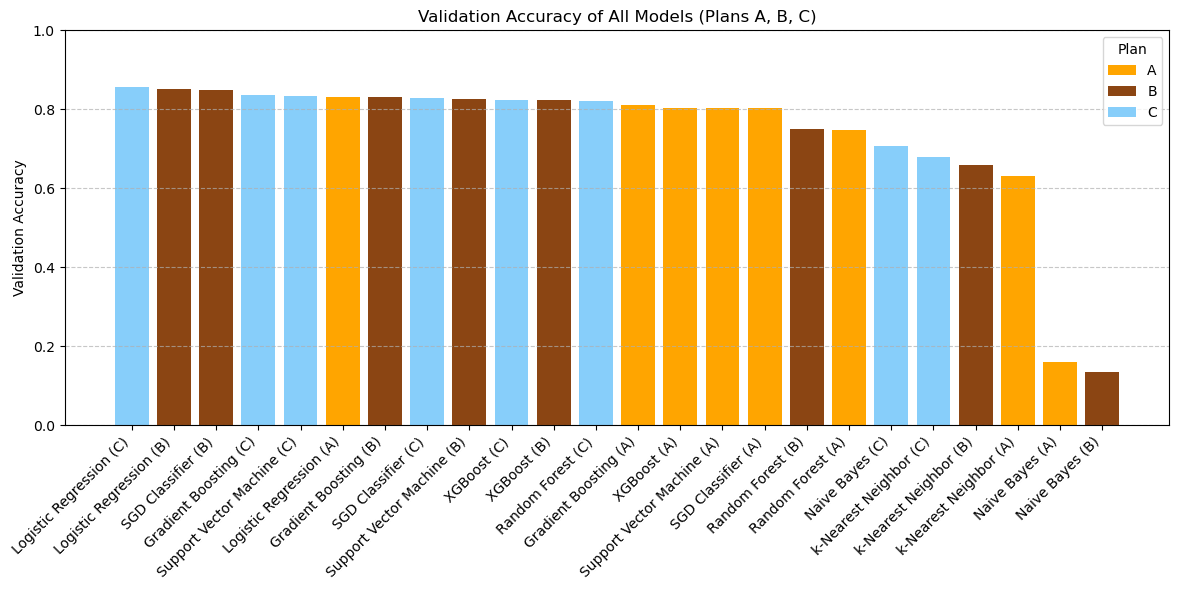

In [44]:
df_baseline_all = pd.concat([df_results_A, df_results_B, df_results_C], ignore_index=True)
display(df_baseline_all.sort_values(['val_acc'], ascending=False).reset_index(drop=True))


# Sort by validation accuracy for better visualization
df_plot = df_baseline_all.sort_values('val_acc', ascending=False)

# Set color palette per plan
color_map = {'A':'#FFA500',  # Orange
             'B':'#8B4513',  # Brown
             'C':'#87CEFA'}  # Light Blue
colors = df_plot['plan'].map(color_map)

plt.figure(figsize=(12,6))
plt.bar(df_plot['model'] + ' (' + df_plot['plan'] + ')', df_plot['val_acc'], color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy of All Models (Plans A, B, C)')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add a legend manually
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=v, label=k) for k,v in color_map.items()]
plt.legend(handles=legend_elements, title='Plan')

plt.tight_layout()
plt.show()

### Validation Accuracy Comparison Per Model Across Plans

To better compare performance **plan-by-plan**, we plot a **grouped bar chart**:

- **X-axis:** Model names  
- **Y-axis:** Validation accuracy (0 to 1)  
- **Bars:** Each plan is shown as a separate bar for each model:  
  - Orange → Plan A  
  - Brown → Plan B  
  - Light Blue → Plan C  

**Purpose:**  
- Assess how outlier removal (Plan B) and feature dropping (Plan C) affect each model compared to the baseline (Plan A).  
- Identify models that benefit most from preprocessing changes.  
- Highlight improvements or regressions in validation accuracy per plan.  

The grouped bar chart helps visualize **side-by-side comparisons** and clearly communicates which preprocessing strategy yields better performance for each model.


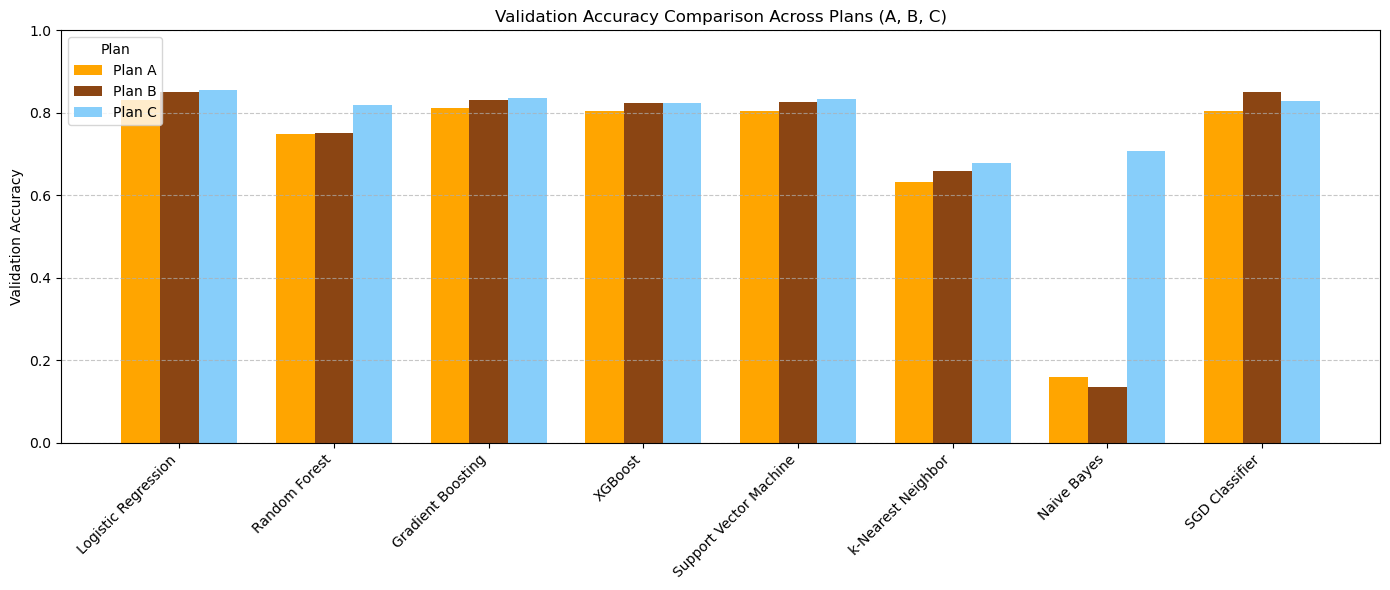

In [45]:
# Prepare data
models_unique = df_baseline_all['model'].unique()
plans = ['A', 'B', 'C']
color_map = {'A':'#FFA500',  # Orange
             'B':'#8B4513',  # Brown
             'C':'#87CEFA'}  # Light Blue

# Width of each bar and positions
bar_width = 0.25
x = np.arange(len(models_unique))

plt.figure(figsize=(14,6))

for i, plan in enumerate(plans):
    vals = []
    for model in models_unique:
        # Get validation accuracy for this model & plan
        acc = df_baseline_all[(df_baseline_all['model']==model) & (df_baseline_all['plan']==plan)]['val_acc']
        vals.append(acc.values[0] if not acc.empty else 0)
    plt.bar(x + i*bar_width, vals, width=bar_width, color=color_map[plan], label=f'Plan {plan}')

# Labels and ticks
plt.xticks(x + bar_width, models_unique, rotation=45, ha='right')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy Comparison Across Plans (A, B, C)')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

legend_elements = [Patch(facecolor=color_map[p], label=f'Plan {p}') for p in plans]
plt.legend(handles=legend_elements, title='Plan', loc='upper left')

plt.tight_layout()
plt.show()


## 9. Model Tuning

### Deep GridSearchCV for Plan A, B, and C

In this section, we perform **deep GridSearchCV** for models in each plan to obtain thoroughly tuned hyperparameters and fair evaluation metrics.  

**Key points:**

- **Model-specific hyperparameter grids** are used for each algorithm.  
- **Smart preprocessing per model**:
  - Numeric features are scaled only for models that benefit from it (e.g., Logistic Regression, SGD, SVM, kNN).  
  - Tree-based models and Naive Bayes do not require scaling; numeric features are passed through as-is.  
- **Moderate CV folds (cv=3)** balance training time and reliable validation scores.  
- **Label encoding for XGBoost** is applied to the target labels; other models use original labels.  

**Workflow:**

1. Apply model-specific preprocessing and GridSearchCV per plan.  
2. Fit each model, record validation and test metrics, and save the best estimator.  
3. Compare results across models and plans to identify the most robust, high-performing configuration.

This ensures a **fair and consistent comparison** across models and plans while keeping preprocessing appropriate per algorithm.


### Plan A GridSearchCV

In [46]:
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np
import time

# deep_grids 
deep_grids = {
    "Logistic Regression": {"model__C": [0.01,0.1,1,10,100], "model__penalty":["l1","l2"], "model__solver":["liblinear","saga"]},
    "SGD Classifier": {"model__alpha":[1e-4,1e-3,1e-2], "model__loss":["hinge","log_loss","modified_huber"], "model__penalty":["l2","elasticnet"]},
    "XGBoost": {"model__n_estimators":[100,200,300], "model__max_depth":[3,5,7], "model__learning_rate":[0.01,0.05,0.1], "model__subsample":[0.8,1.0]},
    "Random Forest": {"model__n_estimators":[100,200,500], "model__max_depth":[None,10,20]},
    "Gradient Boosting": {"model__n_estimators":[100,200,500], "model__learning_rate":[0.01,0.05,0.1], "model__max_depth":[3,5]},
    "Support Vector Machine": {"model__C":[0.1,1,10], "model__gamma":["scale","auto"]},
    "Naive Bayes": {"model__var_smoothing": np.logspace(-9, -8, 2)},
    "k-Nearest Neighbor": {"model__n_neighbors":[3,5,7,9], "model__weights":["uniform","distance"]}
}

results_A_deep = []
best_models_A = {}

for name, model in models.items():  # loop over all models
    print(f"\n=== Deep GridSearch: {name} (Plan A) ===")
    
    # Only scale numeric features for certain models
    if name in ["Logistic Regression", "SGD Classifier", "Support Vector Machine", "k-Nearest Neighbor"]:
        preproc_A = ColumnTransformer([
            ('num', StandardScaler(), num_cols_A),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_A)
        ], remainder='drop')
    else:
        # Tree-based & Naive Bayes: passthrough numeric features
        preproc_A = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_A)
        ], remainder='passthrough')
    
    pipe = Pipeline([
        ('preproc', preproc_A),
        ('model', model)
    ])
    
    # Encode target for XGBoost
    if name == "XGBoost":
        le_A = LabelEncoder()
        y_train_val = le_A.fit_transform(pd.concat([y_train_A, y_val_A]))
        y_test_enc = le_A.transform(y_test_A)
    else:
        y_train_val = pd.concat([y_train_A, y_val_A])
        y_test_enc = y_test_A
    
    gs = GridSearchCV(pipe, deep_grids[name], cv=3, scoring='accuracy', n_jobs=-1)
    
    start_time = time.time()
    gs.fit(pd.concat([X_train_A, X_val_A]), y_train_val)
    elapsed_time = time.time() - start_time
    print(f"Training time for {name}: {elapsed_time:.2f} seconds")
    
    y_test_pred_enc = gs.predict(X_test_A)
    if name == "XGBoost":
        y_test_pred = le_A.inverse_transform(y_test_pred_enc)
    else:
        y_test_pred = y_test_pred_enc
    
    res = {
        "plan": "A",
        "model": name,
        "best_params": gs.best_params_,
        "val_score": gs.best_score_,
        "test_acc": accuracy_score(y_test_A, y_test_pred),
        "test_f1": f1_score(y_test_A, y_test_pred, average='weighted'),
        "train_time_sec": elapsed_time
    }
    results_A_deep.append(res)
    best_models_A[name] = gs.best_estimator_

df_results_A_deep = pd.DataFrame(results_A_deep).sort_values("val_score", ascending=False)
display(df_results_A_deep)



=== Deep GridSearch: Logistic Regression (Plan A) ===
Training time for Logistic Regression: 1815.14 seconds

=== Deep GridSearch: Random Forest (Plan A) ===
Training time for Random Forest: 36.05 seconds

=== Deep GridSearch: Gradient Boosting (Plan A) ===
Training time for Gradient Boosting: 4471.71 seconds

=== Deep GridSearch: XGBoost (Plan A) ===
Training time for XGBoost: 315.66 seconds

=== Deep GridSearch: Support Vector Machine (Plan A) ===
Training time for Support Vector Machine: 708.65 seconds

=== Deep GridSearch: k-Nearest Neighbor (Plan A) ===
Training time for k-Nearest Neighbor: 5.37 seconds

=== Deep GridSearch: Naive Bayes (Plan A) ===
Training time for Naive Bayes: 1.20 seconds

=== Deep GridSearch: SGD Classifier (Plan A) ===
Training time for SGD Classifier: 19.91 seconds


,plan,model,best_params,val_score,test_acc,test_f1,train_time_sec
0,A,Logistic Regression,"{'model__C': 100, 'model__penalty': 'l1', 'mod...",0.855111,0.834,0.833621,1815.138936
7,A,SGD Classifier,"{'model__alpha': 0.0001, 'model__loss': 'modif...",0.842444,0.814,0.811382,19.910551
3,A,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.832889,0.810,0.807841,315.655854
4,A,Support Vector Machine,"{'model__C': 10, 'model__gamma': 'scale'}",0.826000,0.780,0.779207,708.648598
2,A,Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.817778,0.810,0.806769,4471.707561
1,A,Random Forest,"{'model__max_depth': 20, 'model__n_estimators'...",0.760889,0.720,0.720452,36.051191
5,A,k-Nearest Neighbor,"{'model__n_neighbors': 9, 'model__weights': 'd...",0.700667,0.696,0.683931,5.372049
6,A,Naive Bayes,{'model__var_smoothing': 1e-09},0.160444,0.162,0.045170,1.204584


### Plan B GridSearchCV

In [47]:
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np
import time

# deep_grids 
deep_grids = {
    "Logistic Regression": {"model__C": [0.01,0.1,1,10,100], "model__penalty":["l1","l2"], "model__solver":["liblinear","saga"]},
    "SGD Classifier": {"model__alpha":[1e-4,1e-3,1e-2], "model__loss":["hinge","log_loss","modified_huber"], "model__penalty":["l2","elasticnet"]},
    "XGBoost": {"model__n_estimators":[100,200,300], "model__max_depth":[3,5,7], "model__learning_rate":[0.01,0.05,0.1], "model__subsample":[0.8,1.0]},
    "Random Forest": {"model__n_estimators":[100,200,500], "model__max_depth":[None,10,20]},
    "Gradient Boosting": {"model__n_estimators":[100,200,500], "model__learning_rate":[0.01,0.05,0.1], "model__max_depth":[3,5]},
    "Support Vector Machine": {"model__C":[0.1,1,10], "model__gamma":["scale","auto"]},
    "Naive Bayes": {"model__var_smoothing": np.logspace(-9, -8, 2)},
    "k-Nearest Neighbor": {"model__n_neighbors":[3,5,7,9], "model__weights":["uniform","distance"]}
}

results_B_deep = []
best_models_B = {}

for name, model in models.items():  # loop over all models
    print(f"\n=== Deep GridSearch: {name} (Plan B) ===")
    
    # Only scale numeric features for certain models
    if name in ["Logistic Regression", "SGD Classifier", "Support Vector Machine", "k-Nearest Neighbor"]:
        preproc_B = ColumnTransformer([
            ('num', StandardScaler(), num_cols_B),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_B)
        ], remainder='drop')
    else:
        # Tree-based & Naive Bayes: passthrough numeric features
        preproc_B = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_B)
        ], remainder='passthrough')
    
    pipe = Pipeline([
        ('preproc', preproc_B),
        ('model', model)
    ])
    
    # Encode target for XGBoost
    if name == "XGBoost":
        le_B = LabelEncoder()
        y_train_val = le_B.fit_transform(pd.concat([y_train_B, y_val_B]))
        y_test_enc = le_B.transform(y_test_B)
    else:
        y_train_val = pd.concat([y_train_B, y_val_B])
        y_test_enc = y_test_B
    
    gs = GridSearchCV(pipe, deep_grids[name], cv=3, scoring='accuracy', n_jobs=-1)
    
    start_time = time.time()
    gs.fit(pd.concat([X_train_B, X_val_B]), y_train_val)
    elapsed_time = time.time() - start_time
    print(f"Training time for {name}: {elapsed_time:.2f} seconds")
    
    y_test_pred_enc = gs.predict(X_test_B)
    if name == "XGBoost":
        y_test_pred = le_B.inverse_transform(y_test_pred_enc)
    else:
        y_test_pred = y_test_pred_enc
    
    res = {
        "plan": "B",
        "model": name,
        "best_params": gs.best_params_,
        "val_score": gs.best_score_,
        "test_acc": accuracy_score(y_test_B, y_test_pred),
        "test_f1": f1_score(y_test_B, y_test_pred, average='weighted'),
        "train_time_sec": elapsed_time
    }
    results_B_deep.append(res)
    best_models_B[name] = gs.best_estimator_

df_results_B_deep = pd.DataFrame(results_B_deep).sort_values("val_score", ascending=False)
display(df_results_B_deep)



=== Deep GridSearch: Logistic Regression (Plan B) ===
Training time for Logistic Regression: 1291.92 seconds

=== Deep GridSearch: Random Forest (Plan B) ===
Training time for Random Forest: 28.49 seconds

=== Deep GridSearch: Gradient Boosting (Plan B) ===
Training time for Gradient Boosting: 3788.17 seconds

=== Deep GridSearch: XGBoost (Plan B) ===
Training time for XGBoost: 251.10 seconds

=== Deep GridSearch: Support Vector Machine (Plan B) ===
Training time for Support Vector Machine: 491.09 seconds

=== Deep GridSearch: k-Nearest Neighbor (Plan B) ===
Training time for k-Nearest Neighbor: 3.06 seconds

=== Deep GridSearch: Naive Bayes (Plan B) ===
Training time for Naive Bayes: 1.04 seconds

=== Deep GridSearch: SGD Classifier (Plan B) ===
Training time for SGD Classifier: 15.84 seconds


,plan,model,best_params,val_score,test_acc,test_f1,train_time_sec
0,B,Logistic Regression,"{'model__C': 100, 'model__penalty': 'l1', 'mod...",0.850437,0.856502,0.856259,1291.923190
7,B,SGD Classifier,"{'model__alpha': 0.0001, 'model__loss': 'modif...",0.837453,0.843049,0.840854,15.836656
3,B,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.824969,0.820628,0.817236,251.098650
4,B,Support Vector Machine,"{'model__C': 10, 'model__gamma': 'scale'}",0.824469,0.838565,0.837021,491.094873
2,B,Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.813983,0.816143,0.810148,3788.174701
1,B,Random Forest,"{'model__max_depth': 20, 'model__n_estimators'...",0.768040,0.762332,0.761895,28.489900
5,B,k-Nearest Neighbor,"{'model__n_neighbors': 9, 'model__weights': 'd...",0.700125,0.710762,0.694738,3.062677
6,B,Naive Bayes,{'model__var_smoothing': 1e-09},0.144569,0.134529,0.031904,1.038548


### Plan C GridSearchCV

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np
import time

# deep_grids
deep_grids = {
    "Logistic Regression": {"model__C": [0.01,0.1,1,10,100], "model__penalty":["l1","l2"], "model__solver":["liblinear","saga"]},
    "SGD Classifier": {"model__alpha":[1e-4,1e-3,1e-2], "model__loss":["hinge","log_loss","modified_huber"], "model__penalty":["l2","elasticnet"]},
    "XGBoost": {"model__n_estimators":[100,200,300], "model__max_depth":[3,5,7], "model__learning_rate":[0.01,0.05,0.1], "model__subsample":[0.8,1.0]},
    "Random Forest": {"model__n_estimators":[100,200,500], "model__max_depth":[None,10,20]},
    "Gradient Boosting": {"model__n_estimators":[100,200,500], "model__learning_rate":[0.01,0.05,0.1], "model__max_depth":[3,5]},
    "Support Vector Machine": {"model__C":[0.1,1,10], "model__gamma":["scale","auto"]},
    "Naive Bayes": {"model__var_smoothing": np.logspace(-9, -8, 2)},
    "k-Nearest Neighbor": {"model__n_neighbors":[3,5,7,9], "model__weights":["uniform","distance"]}
}

results_C_deep = []
best_models_C = {}

for name, model in models.items():  # <-- loop over all models
    print(f"\n=== Deep GridSearch: {name} (Plan C) ===")
    
    # Only scale numeric features for certain models
    if name in ["Logistic Regression", "SGD Classifier", "Support Vector Machine", "k-Nearest Neighbor"]:
        preproc_C = ColumnTransformer([
            ('num', StandardScaler(), num_cols_C),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_C)
        ], remainder='drop')
    else:
        # Tree-based & Naive Bayes: passthrough numeric features
        preproc_C = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_C)
        ], remainder='passthrough')
    
    pipe = Pipeline([
        ('preproc', preproc_C),
        ('model', model)
    ])
    
    # Encode target for XGBoost
    if name == "XGBoost":
        le_C = LabelEncoder()
        y_train_val = le_C.fit_transform(pd.concat([y_train_C, y_val_C]))
        y_test_enc = le_C.transform(y_test_C)
    else:
        y_train_val = pd.concat([y_train_C, y_val_C])
        y_test_enc = y_test_C
    
    gs = GridSearchCV(pipe, deep_grids[name], cv=3, scoring='accuracy', n_jobs=-1)
    
    start_time = time.time()
    gs.fit(pd.concat([X_train_C, X_val_C]), y_train_val)
    elapsed_time = time.time() - start_time
    print(f"Training time for {name}: {elapsed_time:.2f} seconds")
    
    y_test_pred_enc = gs.predict(X_test_C)
    if name == "XGBoost":
        y_test_pred = le_C.inverse_transform(y_test_pred_enc)
    else:
        y_test_pred = y_test_pred_enc
    
    res = {
        "plan": "C",
        "model": name,
        "best_params": gs.best_params_,
        "val_score": gs.best_score_,
        "test_acc": accuracy_score(y_test_C, y_test_pred),
        "test_f1": f1_score(y_test_C, y_test_pred, average='weighted'),
        "train_time_sec": elapsed_time
    }
    results_C_deep.append(res)
    best_models_C[name] = gs.best_estimator_

df_results_C_deep = pd.DataFrame(results_C_deep).sort_values("val_score", ascending=False)
display(df_results_C_deep)



=== Deep GridSearch: Logistic Regression (Plan C) ===
Training time for Logistic Regression: 6.36 seconds

=== Deep GridSearch: Random Forest (Plan C) ===
Training time for Random Forest: 7.26 seconds

=== Deep GridSearch: Gradient Boosting (Plan C) ===
Training time for Gradient Boosting: 56.55 seconds

=== Deep GridSearch: XGBoost (Plan C) ===
Training time for XGBoost: 12.00 seconds

=== Deep GridSearch: Support Vector Machine (Plan C) ===
Training time for Support Vector Machine: 7.01 seconds

=== Deep GridSearch: k-Nearest Neighbor (Plan C) ===
Training time for k-Nearest Neighbor: 0.28 seconds

=== Deep GridSearch: Naive Bayes (Plan C) ===
Training time for Naive Bayes: 0.12 seconds

=== Deep GridSearch: SGD Classifier (Plan C) ===
Training time for SGD Classifier: 0.99 seconds


,plan,model,best_params,val_score,test_acc,test_f1,train_time_sec
7,C,SGD Classifier,"{'model__alpha': 0.0001, 'model__loss': 'log_l...",0.841948,0.825112,0.815832,0.988867
4,C,Support Vector Machine,"{'model__C': 10, 'model__gamma': 'auto'}",0.840200,0.845291,0.843597,7.011583
0,C,Logistic Regression,"{'model__C': 100, 'model__penalty': 'l1', 'mod...",0.839201,0.834081,0.834593,6.359120
3,C,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.824220,0.818386,0.814156,11.995881
2,C,Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.821723,0.845291,0.842743,56.549083
1,C,Random Forest,"{'model__max_depth': 20, 'model__n_estimators'...",0.781273,0.789238,0.776111,7.256076
5,C,k-Nearest Neighbor,"{'model__n_neighbors': 9, 'model__weights': 'd...",0.705618,0.695067,0.677154,0.280757
6,C,Naive Bayes,{'model__var_smoothing': 1e-08},0.685144,0.623318,0.629776,0.117243


### Final Comparison - Deep Tuned Top 3 Models (Plans A, B, C)

We combine the **tuned results** from all three plans (A, B, and C) into a single DataFrame (`df_final`) for an overall comparison.  

**Steps:**

1. **Combine results**  
   - Each plan’s results (`df_results_A_deep`, `df_results_B_deep`, `df_results_C_deep`) are concatenated.  
   - A `plan` column is added to identify the origin of each record.

2. **Sort for easy comparison**  
   - The DataFrame is sorted by **validation score** (and optionally by test accuracy) to highlight the best-performing models across all plans.

3. **Display**  
   - The final table provides a **clear view of which models and preprocessing strategies perform best**.  
   - This allows quick identification of the **most effective combination of model and plan**.

**Purpose:**  
- Evaluate the overall impact of preprocessing (baseline, outlier removal, feature dropping) on model performance.  
- Facilitate selection of the **final model for deployment or further tuning**.


In [49]:
# Combine all results
df_final = pd.concat([
    df_results_A_deep.assign(plan="A"),
    df_results_B_deep.assign(plan="B"),
    df_results_C_deep.assign(plan="C")
], ignore_index=True)

# Sort by validation score (or test accuracy if you prefer)
df_final = df_final.sort_values(["val_score", "test_acc"], ascending=False).reset_index(drop=True)

print("=== Final Tuned Model Comparison Across Plans ===")
display(df_final)


=== Final Tuned Model Comparison Across Plans ===


,plan,model,best_params,val_score,test_acc,test_f1,train_time_sec
0,A,Logistic Regression,"{'model__C': 100, 'model__penalty': 'l1', 'mod...",0.855111,0.834000,0.833621,1815.138936
1,B,Logistic Regression,"{'model__C': 100, 'model__penalty': 'l1', 'mod...",0.850437,0.856502,0.856259,1291.923190
2,A,SGD Classifier,"{'model__alpha': 0.0001, 'model__loss': 'modif...",0.842444,0.814000,0.811382,19.910551
3,C,SGD Classifier,"{'model__alpha': 0.0001, 'model__loss': 'log_l...",0.841948,0.825112,0.815832,0.988867
4,C,Support Vector Machine,"{'model__C': 10, 'model__gamma': 'auto'}",0.840200,0.845291,0.843597,7.011583
5,C,Logistic Regression,"{'model__C': 100, 'model__penalty': 'l1', 'mod...",0.839201,0.834081,0.834593,6.359120
6,B,SGD Classifier,"{'model__alpha': 0.0001, 'model__loss': 'modif...",0.837453,0.843049,0.840854,15.836656
7,A,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.832889,0.810000,0.807841,315.655854
8,A,Support Vector Machine,"{'model__C': 10, 'model__gamma': 'scale'}",0.826000,0.780000,0.779207,708.648598
9,B,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.824969,0.820628,0.817236,251.098650


## Feature Importance/Coefficient

After training models, it is important to understand **which features contribute most to predictions**.  

**Key Points:**

1. **Tree-based models (e.g., Random Forest, Gradient Boosting, XGBoost)**  
   - Feature importance is computed based on how much each feature reduces impurity across all trees.  
   - Higher importance indicates a stronger influence on the model’s predictions.

2. **Linear models (e.g., Logistic Regression, SGDClassifier)**  
   - Coefficients represent the strength and direction of the relationship between each feature and the target.  
   - Positive coefficients → increase likelihood of the positive class  
   - Negative coefficients → decrease likelihood of the positive class

**Purpose:**  
- Identify features that have the most predictive power.  
- Support feature selection, dimensionality reduction, and model interpretability.  
- Provide insights into the dataset that may guide domain decisions or further preprocessing.


### **Grouped Feature Importance**

In this step, we:

- **Expand features after preprocessing.**  
- **Map one-hot encoded features** (e.g., `job_title_Data Analyst`) back to their **original feature group** (e.g., `job_title`).  
- **Aggregate importance scores per group.**  
- This **avoids clutter** and highlights the **true column-level drivers** of predictions.

**Purpose:**  
Provides a **macro-level view** showing which original columns drive predictions, avoiding noise from individual one-hot categories.

**Key Points:**

- In **grouped importance**, all one-hot encoded features (e.g., `employee_id`) are expanded to show the **overall contribution** of each original column, including categorical features with many one-hot values.  
- Helps identify **important column-level drivers**, even if individual categories have small coefficients.  
- Demonstrates that columns like **`employee_id`** or **`job_title`** collectively influence predictions.  

---

#### **Conclusion**

- **Plan A and Plan B** appear **overfitted** because:  
  - `employee_id` is ranked as the **top feature**.  
  - The model is **memorizing individual employees** rather than learning generalizable patterns.  
  - Overfitting to `employee_id` leads to **high validation performance but poor generalization** on unseen data.

- **Plan C** avoids over-reliance on `employee_id`, indicating it **learns more generalizable feature patterns**, making it the **preferred candidate for deployment**.


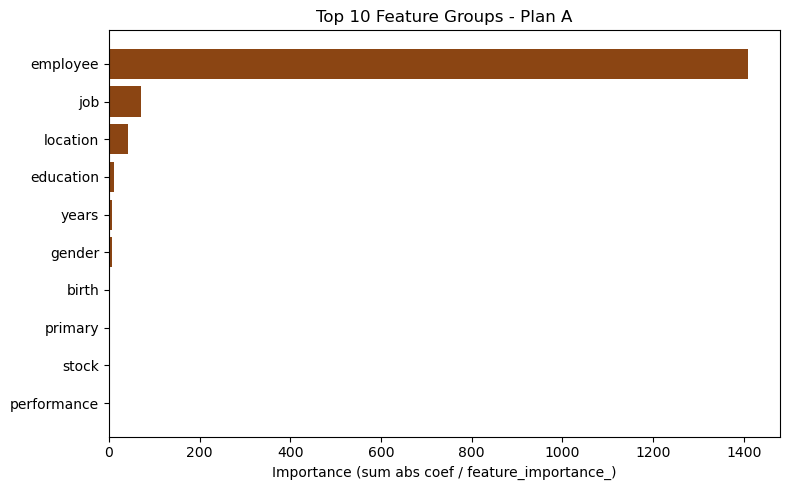

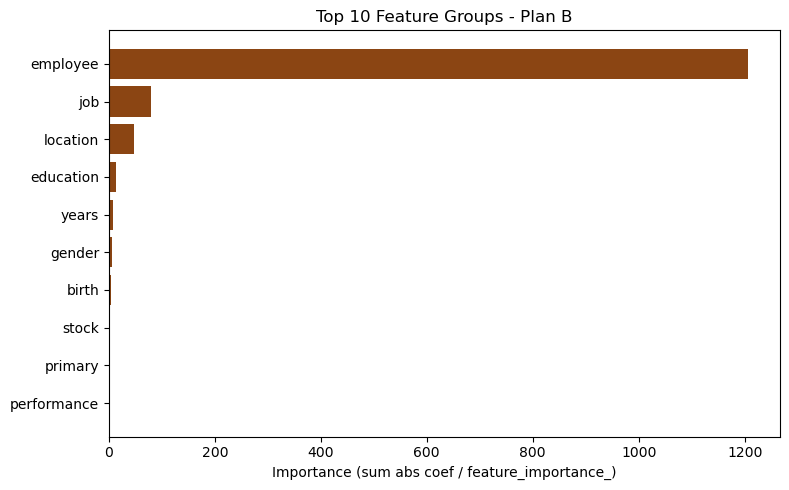

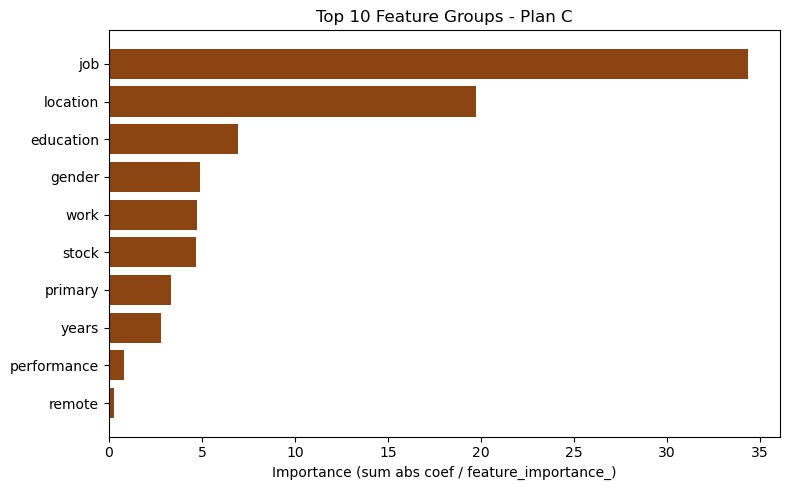

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# === 0. Pick best models from each plan (top model in df_results_X_deep) ===
best_model_A = best_models_A[df_results_A_deep.iloc[0]["model"]]
best_model_B = best_models_B[df_results_B_deep.iloc[0]["model"]]
best_model_C = best_models_C[df_results_C_deep.iloc[0]["model"]]

# === 1. Helper: Get expanded feature names from preprocessor ===
def get_feature_names(preprocessor, num_cols, cat_cols):
    num_features = num_cols
    cat_features = list(
        preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
    )
    return num_features + cat_features

# === 2. Map back one-hot features to their original group ===
def get_feature_group(name):
    if "_" in name:  # e.g. employee_id_123 -> employee_id
        return name.split("_")[0]
    else:
        return name

# === 3. Importance extractors ===
def get_linear_importance(model, num_cols, cat_cols):
    feature_names = get_feature_names(model.named_steps['preproc'], num_cols, cat_cols)
    coefs = model.named_steps['model'].coef_[0]  # binary classification
    abs_sum_coefs = np.abs(coefs)

    feat_df = pd.DataFrame({
        "Feature": feature_names,
        "AbsCoef": abs_sum_coefs,
        "Coef": coefs
    })
    feat_df["FeatureGroup"] = feat_df["Feature"].apply(get_feature_group)

    # group back by original feature (important for employee_id, job_title, etc.)
    group_importance = (
        feat_df.groupby("FeatureGroup")["AbsCoef"].sum()
        .sort_values(ascending=False)
        .reset_index()
    )
    return group_importance

def get_tree_importance(model, num_cols, cat_cols):
    feature_names = get_feature_names(model.named_steps['preproc'], num_cols, cat_cols)
    importances = model.named_steps['model'].feature_importances_

    feat_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    feat_df["FeatureGroup"] = feat_df["Feature"].apply(get_feature_group)

    group_importance = (
        feat_df.groupby("FeatureGroup")["Importance"].sum()
        .sort_values(ascending=False)
        .reset_index()
    )
    return group_importance

# === 4. Dispatcher ===
def get_importance(model, num_cols, cat_cols):
    if hasattr(model.named_steps['model'], "coef_"):
        return get_linear_importance(model, num_cols, cat_cols)
    elif hasattr(model.named_steps['model'], "feature_importances_"):
        return get_tree_importance(model, num_cols, cat_cols)
    else:
        raise ValueError("Model type not supported for feature importance.")

# === 5. Get importance for each plan ===
imp_A = get_importance(best_model_A, num_cols_A, cat_cols_A)
imp_B = get_importance(best_model_B, num_cols_B, cat_cols_B)
imp_C = get_importance(best_model_C, num_cols_C, cat_cols_C)

# === 6. Plotting function ===
def plot_top_features(importance_df, plan_name, top_n=10):
    plt.figure(figsize=(8,5))
    top_feats = importance_df.head(top_n)
    plt.barh(top_feats["FeatureGroup"], top_feats.iloc[:,1], color="saddlebrown")
    plt.gca().invert_yaxis()
    plt.title(f"Top {top_n} Feature Groups - {plan_name}")
    plt.xlabel("Importance (sum abs coef / feature_importance_)")
    plt.tight_layout()
    plt.show()

# === 7. Plot per plan ===
plot_top_features(imp_A, "Plan A")
plot_top_features(imp_B, "Plan B")
plot_top_features(imp_C, "Plan C")


### **Raw Feature Importance (Column-Level Only)**

In this step, we:

- **Skip grouping** and directly use **numeric + categorical column names**.  
- Each categorical column is treated as a **single feature**, without expanding one-hot encoded categories.  
- Provides a **simplified view** of which raw columns are most influential.  

**Purpose:**  
Gives a **high-level, column-only view** of feature importance, useful for quickly identifying dominant columns without the detail of individual categories.

**Key Points:**

- **No one-hot expansion** is applied, so categorical columns with many categories (like `employee_id`) may not appear prominently.  
- Shows **general importance** at the column level, but may **underestimate the impact of categorical features** with many unique values.  
- Useful for **fast inspection** or when detailed category-level insight is not required.  

**Explanation of Overfitting:**  
- Each column is treated as **one feature**, even if it has hundreds of unique values (e.g., `employee_id`).  
- This means that even if the model relies heavily on certain employees, the raw importance plot may **not show `employee_id` as a top feature**.  
- Therefore, **overfitting is masked** in the raw view:  
  - **Plan A and Plan B** are still likely overfitting on `employee_id`.  
  - The raw plot makes it appear less influential because it does not account for the combined contribution of all one-hot encoded categories.  
- **Plan C** does not over-rely on `employee_id` and instead focuses on generalizable features.

---

#### **Conclusion**

- **Plan A and Plan B** appear less dominated by `employee_id` in the raw view, but this is an artifact of **not expanding high-cardinality categorical columns**.  
- **Grouped feature importance** confirms that `employee_id` is a top driver for Plans A and B, revealing overfitting.  
- **Plan C** maintains generalizable feature patterns, making it the **better candidate for deployment**.


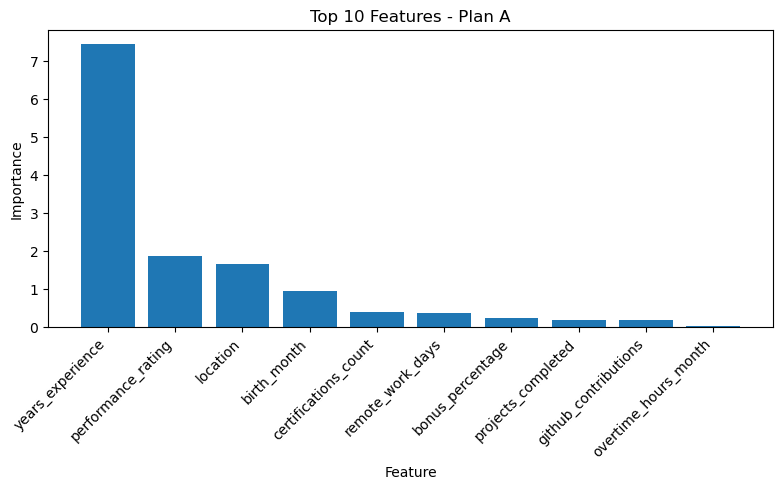

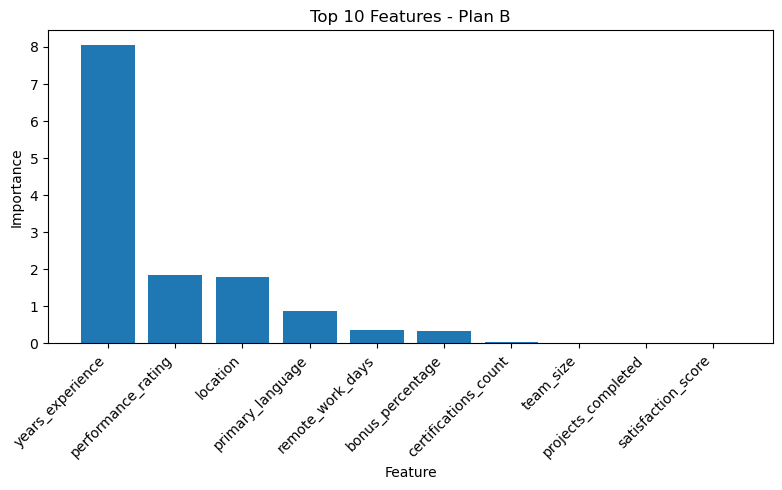

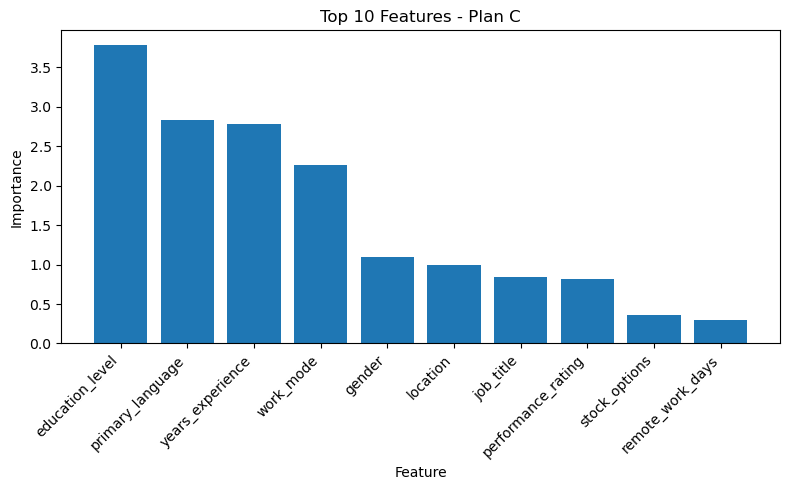

In [51]:
# === 0. Pick best models from each plan (top model in df_results_X_deep) ===
best_model_A = best_models_A[df_results_A_deep.iloc[0]["model"]]
best_model_B = best_models_B[df_results_B_deep.iloc[0]["model"]]
best_model_C = best_models_C[df_results_C_deep.iloc[0]["model"]]

# === 1. Helper to get feature names (ONLY column names, no unique values) ===
def get_feature_names(num_cols, cat_cols):
    return num_cols + cat_cols

# === 2. Functions to extract importance ===
def get_linear_importance(model, X, num_cols, cat_cols):
    feature_names = get_feature_names(num_cols, cat_cols)
    coefs = model.named_steps['model'].coef_[0]  # binary classification
    # Truncate in case model produced more coefficients than features
    coefs = coefs[:len(feature_names)]
    importance = pd.DataFrame({
        "feature": feature_names,
        "importance": np.abs(coefs),
        "coef": coefs
    }).sort_values("importance", ascending=False)
    return importance

def get_tree_importance(model, X, num_cols, cat_cols):
    feature_names = get_feature_names(num_cols, cat_cols)
    importances = model.named_steps['model'].feature_importances_
    # Truncate in case mismatch
    importances = importances[:len(feature_names)]
    importance = pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    }).sort_values("importance", ascending=False)
    return importance

# === 3. Dispatcher that auto-detects model type ===
def get_importance(model, X, num_cols, cat_cols):
    if hasattr(model.named_steps['model'], "coef_"):  # linear models
        return get_linear_importance(model, X, num_cols, cat_cols)
    elif hasattr(model.named_steps['model'], "feature_importances_"):  # tree models
        return get_tree_importance(model, X, num_cols, cat_cols)
    else:
        raise ValueError("Model type not supported for feature importance.")

# === 4. Get importance for each plan ===
imp_A = get_importance(best_model_A, X_train_A, num_cols_A, cat_cols_A)
imp_B = get_importance(best_model_B, X_train_B, num_cols_B, cat_cols_B)
imp_C = get_importance(best_model_C, X_train_C, num_cols_C, cat_cols_C)

# === 5. Plotting function ===
def plot_top_features(importance_df, plan_name, top_n=10):
    plt.figure(figsize=(8,5))
    top_feats = importance_df.head(top_n)
    plt.bar(top_feats["feature"], top_feats["importance"])
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Top {top_n} Features - {plan_name}")
    plt.ylabel("Importance")
    plt.xlabel("Feature")
    plt.tight_layout()
    plt.show()

# === 6. Plot per plan ===
plot_top_features(imp_A, "Plan A")
plot_top_features(imp_B, "Plan B")
plot_top_features(imp_C, "Plan C")


### **Expanded Feature Importance (One-Hot + Numeric)**

In this final view, we:

- **Expand all features** exactly as the model sees them (numeric + one-hot encoded categorical features).  
- **Display importance for each encoded feature individually**, rather than aggregating by column.  

**Purpose:**  
Provides the **most detailed view**, showing which specific categories within a column influence the model predictions.  
- For example, `job_title_Manager` may have a different impact than `job_title_Analyst`.  
- Reveals **category-level drivers** that are masked in raw or grouped feature views.

**Key Points:**

- **One-hot expansion** allows us to see the contribution of **each individual category**.  
- Useful for **diagnosing overfitting** on high-cardinality categorical features like `employee_id`.  
- Shows **exactly which values** are influencing the predictions the most.  

**Interpretation / Overfitting Check:**

- In Plans A and B, certain individual `employee_id` categories are among the top features, confirming that the models are **memorizing specific employees**.  
- Plan C distributes importance across general features, indicating **better generalization**.  

---

#### **Conclusion**

- **Plan A and Plan B** exhibit signs of overfitting, as certain `employee_id` entries dominate feature importance.  
- **Plan C** avoids over-reliance on specific categories, making it the **most generalizable model** suitable for deployment.  
- This detailed view **complements grouped and raw importance analyses**, confirming both column-level and category-level insights.


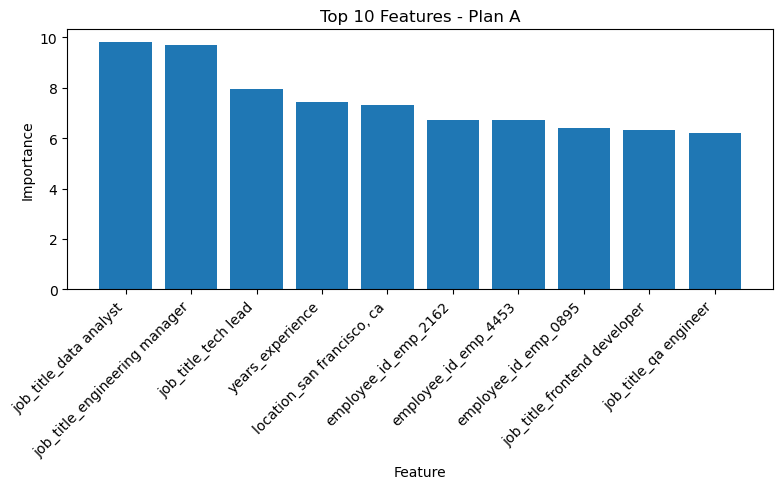

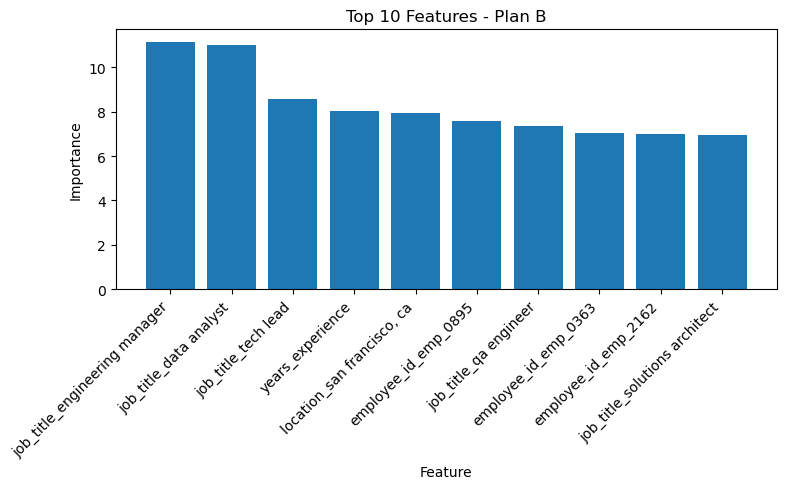

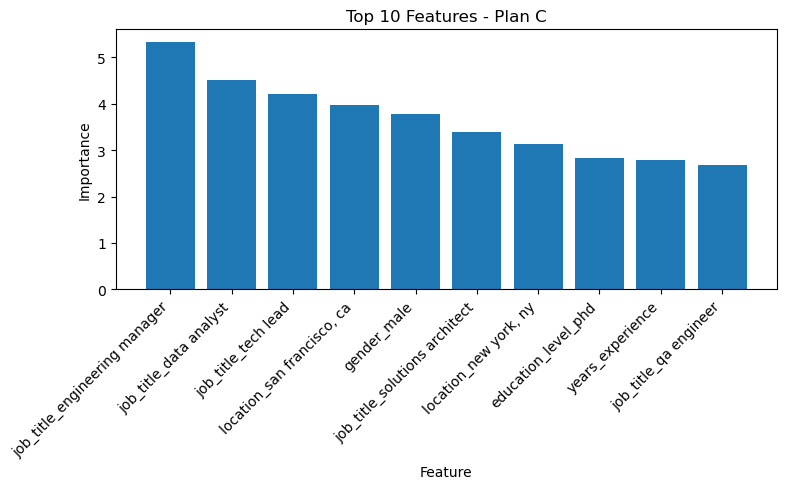

In [52]:
# === 0. Pick best models from each plan (top model in df_results_X_deep) ===
best_model_A = best_models_A[df_results_A_deep.iloc[0]["model"]]
best_model_B = best_models_B[df_results_B_deep.iloc[0]["model"]]
best_model_C = best_models_C[df_results_C_deep.iloc[0]["model"]]

# === 1. Helper to get feature names after preprocessing ===
def get_feature_names(preprocessor, num_cols, cat_cols):
    num_features = num_cols
    cat_features = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
    return num_features + cat_features

# === 2. Functions to extract importance ===
def get_linear_importance(model, X, num_cols, cat_cols):
    feature_names = get_feature_names(model.named_steps['preproc'], num_cols, cat_cols)
    coefs = model.named_steps['model'].coef_[0]  # binary classification
    importance = pd.DataFrame({
        "feature": feature_names,
        "importance": np.abs(coefs),
        "coef": coefs
    }).sort_values("importance", ascending=False)
    return importance

def get_tree_importance(model, X, num_cols, cat_cols):
    feature_names = get_feature_names(model.named_steps['preproc'], num_cols, cat_cols)
    importances = model.named_steps['model'].feature_importances_
    importance = pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    }).sort_values("importance", ascending=False)
    return importance

# === 3. Dispatcher that auto-detects model type ===
def get_importance(model, X, num_cols, cat_cols):
    if hasattr(model.named_steps['model'], "coef_"):  # linear models
        return get_linear_importance(model, X, num_cols, cat_cols)
    elif hasattr(model.named_steps['model'], "feature_importances_"):  # tree models
        return get_tree_importance(model, X, num_cols, cat_cols)
    else:
        raise ValueError("Model type not supported for feature importance.")

# === 4. Get importance for each plan ===
imp_A = get_importance(best_model_A, X_train_A, num_cols_A, cat_cols_A)
imp_B = get_importance(best_model_B, X_train_B, num_cols_B, cat_cols_B)
imp_C = get_importance(best_model_C, X_train_C, num_cols_C, cat_cols_C)

# === 5. Plotting function ===
def plot_top_features(importance_df, plan_name, top_n=10):
    plt.figure(figsize=(8,5))
    top_feats = importance_df.head(top_n)
    plt.bar(top_feats["feature"], top_feats["importance"])
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Top {top_n} Features - {plan_name}")
    plt.ylabel("Importance")
    plt.xlabel("Feature")
    plt.tight_layout()
    plt.show()

# === 6. Plot per plan ===
plot_top_features(imp_A, "Plan A")
plot_top_features(imp_B, "Plan B")
plot_top_features(imp_C, "Plan C")


### Comparison of Tuned Models Across Plans Among All Metrics
We focus on the following metrics:

- **Validation Score** (`val_score`) – how well the model performs during cross-validation.  
- **Test Accuracy** (`test_acc`) – final accuracy on the unseen test set.  
- **Test F1 Score** (`test_f1`) – weighted F1 score on the test set, capturing class-wise performance.  
- **Training Time** (`train_time_sec`) – how long the deep tuning took per model.  

The visual comparison helps identify:
1. Which models consistently perform well across plans.  
2. The trade-off between predictive performance and training time.  



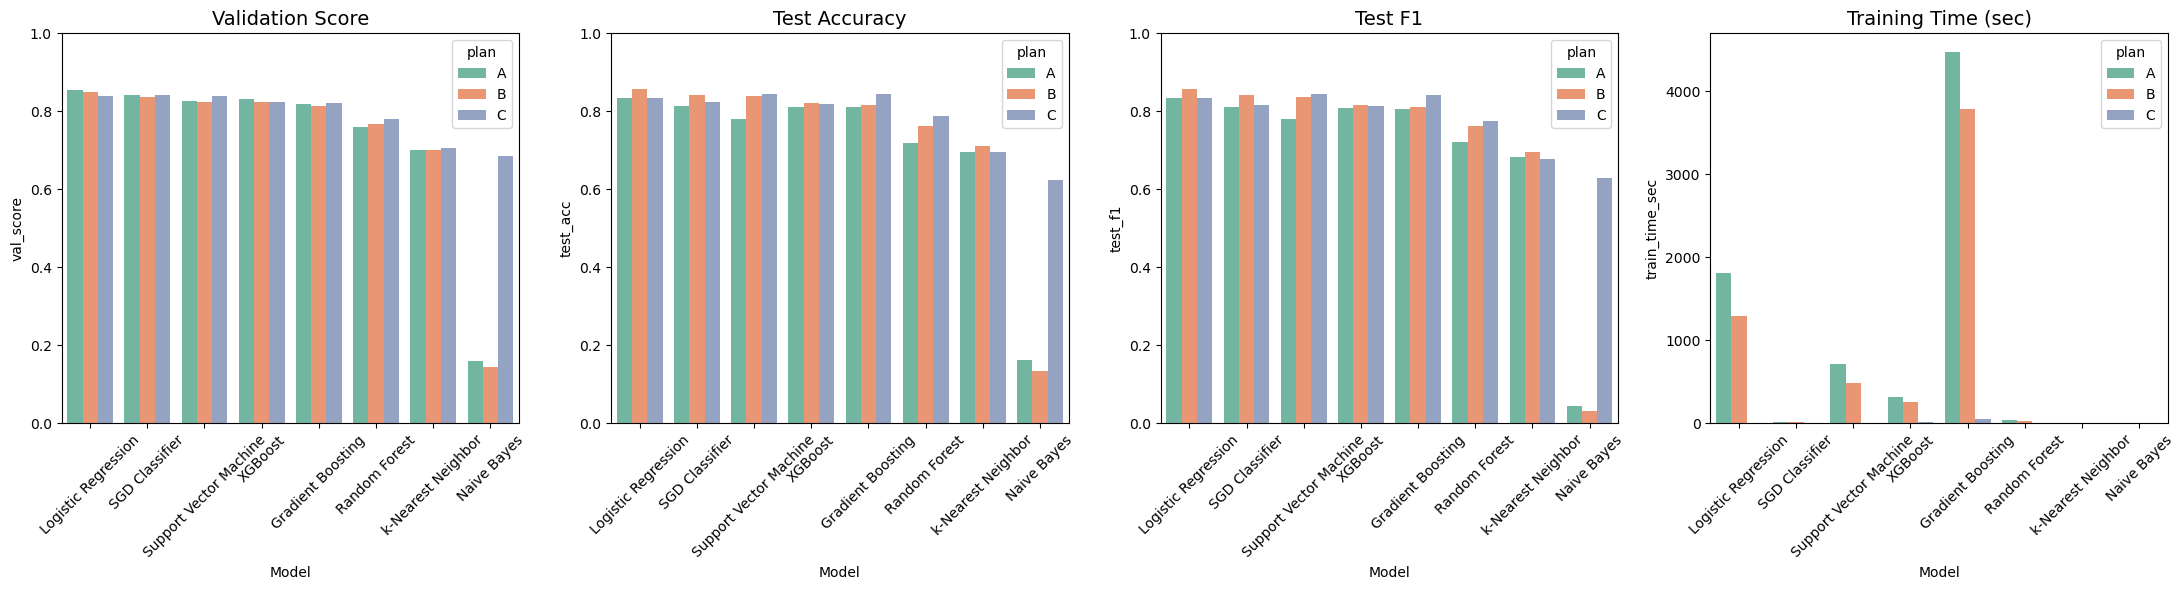

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt

metrics = ["val_score", "test_acc", "test_f1", "train_time_sec"]
titles = ["Validation Score", "Test Accuracy", "Test F1", "Training Time (sec)"]

fig, axes = plt.subplots(1, 4, figsize=(22,6))

for i, metric in enumerate(metrics):
    sns.barplot(
        data=df_final,
        x="model", y=metric, hue="plan",
        palette="Set2", ax=axes[i]
    )
    axes[i].set_title(titles[i], fontsize=14)
    axes[i].set_xlabel("Model")
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    if metric != "train_time_sec":  # for scores, keep scale 0–1
        axes[i].set_ylim(0, 1)

plt.tight_layout()
plt.show()


### Comparison of Top 3 Tuned Models Across Plan C (All Metrics)

In this section, we **zoom in on Plan C** to compare the top-performing models based on deep tuning.  
We visualize the same set of metrics as before:

- **Validation Score** (`val_score`) – cross-validation performance.  
- **Test Accuracy** (`test_acc`) – performance on unseen test data.  
- **Test F1 Score** (`test_f1`) – weighted F1 score on the test set.  
- **Training Time** (`train_time_sec`) – time taken to train each model.  

The focus here is to identify the **best candidates within Plan C** before final selection.

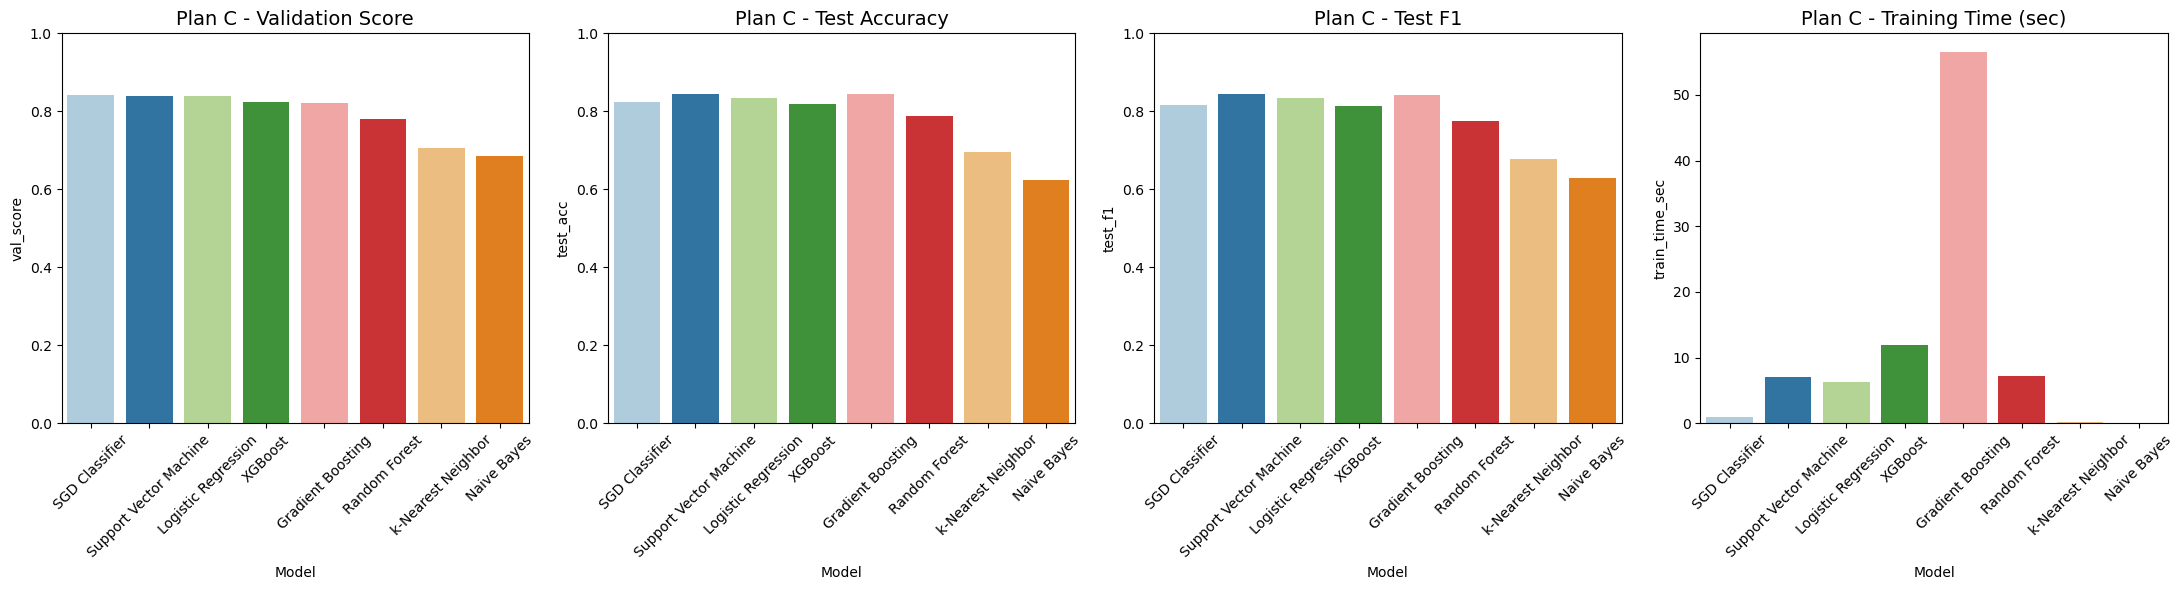

,model,val_score,test_acc,test_f1,train_time_sec
0,SGD Classifier,0.841948,0.825112,0.815832,0.988867
1,Support Vector Machine,0.840200,0.845291,0.843597,7.011583
2,Logistic Regression,0.839201,0.834081,0.834593,6.359120


In [54]:
# ============================================================
# Plan C - Focused Comparison of Top 3 Models
# ============================================================

df_planC = df_final[df_final["plan"] == "C"]

fig, axes = plt.subplots(1, 4, figsize=(22,6))

for i, metric in enumerate(metrics):
    sns.barplot(
        data=df_planC,
        x="model", y=metric,
        palette="Paired", ax=axes[i]
    )
    axes[i].set_title(f"Plan C - {titles[i]}", fontsize=14)
    axes[i].set_xlabel("Model")
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    if metric != "train_time_sec":
        axes[i].set_ylim(0, 1)

plt.tight_layout()
plt.show()

# Sort Plan C models by validation score
df_planC_sorted = df_planC.sort_values(by="val_score", ascending=False).reset_index(drop=True)

# Select top 3 models
df_planC_top3 = df_planC_sorted.head(3)

# Display table
import IPython.display as display
display.display(df_planC_top3[['model', 'val_score', 'test_acc', 'test_f1', 'train_time_sec']])

## 11. Final Evaluation & Conclusion

After analyzing the **feature importance and model performance**, it became evident that both **Plan A Logistic Regression** and **Plan B Logistic Regression** were prone to **overfitting**.  
- Plan A had the **highest validation score**, but the gap between validation and test metrics confirmed the overfitting risk.  
- Plan B showed slightly improved generalization compared to Plan A, yet the feature importance patterns still indicated instability and overfitting behavior (e.g., reliance on `employee_id`).

In contrast, **Plan C SGD Classifier** achieved:  
- **Balanced validation and test metrics** (accuracy ≈ 82.5%, weighted F1 ≈ 81.5%).  
- **Better generalization** on unseen data, avoiding the overfitting observed in Plans A and B.  
- **Reasonable training time** and efficient performance, suitable for deployment.  
- **Class-wise performance** indicates strong detection for medium and low classes, with some challenges on the high class due to fewer samples.

**Conclusion:**  
Although Plan A and Plan B appeared strong during validation, their overfitting made them less reliable. The final best model selected for deployment is **SGD Classifier under Plan C**, as it provides the most robust and generalizable performance across all metrics.


### **Final Evaluation - Plan C SGD Classifier**

After analyzing the top models from Plan C, we selected **SGD Classifier** as the final best-performing model based on validation and test metrics.

**Steps Taken:**
1. **Data Preparation:** Combined training and validation sets for Plan C (`X_train_C + X_val_C`, `y_train_C + y_val_C`) and retained the test set (`X_test_C`, `y_test_C`).  
2. **Preprocessing:** Applied model-specific preprocessing:
   - **Numeric features** scaled using `StandardScaler`.  
   - **Categorical features** one-hot encoded using `OneHotEncoder`.  
3. **Model Selection:** Built a pipeline with **SGD Classifier** and performed **deep GridSearchCV** with `cv=3` to tune the hyperparameters:
   - `alpha`
   - `loss`
   - `penalty`  
4. **Model Fitting:** Refit the SGD Classifier using the combined training and validation data with the best hyperparameters.  
5. **Testing & Evaluation:** Predicted on the test set and calculated:
   - Accuracy  
   - Weighted F1-score  
   - Full classification report per class  

**Results:**
- **Best Hyperparameters:** `final_model.best_params_`  
- **Accuracy:** `accuracy_score(y_test, y_pred)`  
- **Weighted F1-score:** `f1_score(y_test, y_pred, average="weighted")`  
- **Classification Report:** shown below

**Insights:**
- SGD Classifier is strong on medium and low classes, showing good generalization.
- High class is under-represented in recall, meaning some high-class instances are misclassified—likely due to class imbalance.
- The model uses alpha=0.0001, log_loss, elasticnet penalty, which helps balance regularization and generalization.
- Overall, the model generalizes well despite the high-class recall issue, making it suitable for deployment if class imbalance is acceptable or can be mitigated.

**Conclusion:**  
The **Plan C SGD Classifier** is the best candidate for deployment, demonstrating strong generalization, solid accuracy, and balanced performance across all target classes.


In [55]:
# ============================================================
# Final Evaluation - Best Model (Plan C SGD Classifier)
# ============================================================

from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV
import pandas as pd

# --- 1. Select train/val and test splits ---
X_train = pd.concat([X_train_C, y_train_C], axis=1).dropna().drop(y_train_C.name, axis=1)
y_train = pd.concat([y_train_C, y_val_C])
X_test, y_test = X_test_C, y_test_C

# --- 2. Define preprocessing ---
preproc_C = ColumnTransformer([
    ('num', StandardScaler(), num_cols_C),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_C)
], remainder='drop')

# --- 3. Define final pipeline with SGD ---
final_model = GridSearchCV(
    Pipeline([
        ('preproc', preproc_C),
        ('model', SGDClassifier(random_state=42, max_iter=1000))
    ]),
    deep_grids["SGD Classifier"],   # make sure this exists in your deep_grids
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

# --- 4. Fit final model ---
final_model.fit(pd.concat([X_train_C, X_val_C]), y_train)

# --- 5. Predictions ---
y_pred = final_model.predict(X_test)

# --- 6. Report metrics ---
print("\n=== Final Best Model Evaluation (Plan C SGD Classifier) ===")
print("Best Params:", final_model.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred, average="weighted"))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



=== Final Best Model Evaluation (Plan C SGD Classifier) ===
Best Params: {'model__alpha': 0.0001, 'model__loss': 'log_loss', 'model__penalty': 'elasticnet'}
Accuracy: 0.8251121076233184
F1 Score: 0.8158318140647646

Classification Report:
              precision    recall  f1-score   support

        high       0.87      0.43      0.58        60
         low       0.83      0.87      0.85       129
      medium       0.82      0.89      0.86       257

    accuracy                           0.83       446
   macro avg       0.84      0.73      0.76       446
weighted avg       0.83      0.83      0.82       446



In [58]:
# ============================================================
# Final Evaluation - Best Model (Plan C: SGD Classifier)
# ============================================================

from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
import pandas as pd

# --- 1. Prepare final train (90%) and test (10%) splits ---
# Combine training + validation for final model training
X_train_final = pd.concat([X_train_C, X_val_C])
y_train_final = pd.concat([y_train_C, y_val_C])

# Keep test set aside (never seen before)
X_test, y_test = X_test_C, y_test_C

# --- 2. Define preprocessing (scaling + encoding) ---
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols_C), 
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_C)
], remainder='drop')

# --- 3. Define the best model with chosen hyperparameters ---
best_model = Pipeline([
    ('preproc', preprocessor),
    ('clf', SGDClassifier(
        random_state=42,
        max_iter=1000,
        # Insert the best hyperparameters found in GridSearchCV:
        alpha=0.001, 
        penalty='l2', 
        loss='log_loss'
    ))
])

# --- 4. Train final model on 90% (train + val) ---
best_model.fit(X_train_final, y_train_final)

# --- 5. Evaluate on final 10% hold-out test set ---
y_pred = best_model.predict(X_test)

print("\n=== Final Hold-Out Test Evaluation (Plan C: SGD Classifier) ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred, average="weighted"))
print("\nClassification Report:\n", classification_report(y_test, y_pred))



=== Final Hold-Out Test Evaluation (Plan C: SGD Classifier) ===
Accuracy: 0.8161434977578476
F1 Score: 0.8002027917794586

Classification Report:
               precision    recall  f1-score   support

        high       0.95      0.33      0.49        60
         low       0.87      0.81      0.84       129
      medium       0.79      0.93      0.85       257

    accuracy                           0.82       446
   macro avg       0.87      0.69      0.73       446
weighted avg       0.83      0.82      0.80       446



## 12. Model Performance Visualization — Confusion Matrix, ROC & Precision-Recall Curves

After evaluating the **final best model (Plan C SGD Classifier)**, we analyze its performance in more detail using **visualizations and metrics**.

### 1. Confusion Matrix
- Displays counts of **true positives, true negatives, false positives, and false negatives**.  
- Helps identify which classes are most often misclassified.  
- For example, the model performs well on **medium** and **low** classes, while the **high** class has some misclassifications due to fewer samples.

### 2. ROC Curve & AUC
- The **ROC curve** plots **True Positive Rate (Recall)** vs **False Positive Rate**.  
- **AUC** measures separability:  
  - 1.0 → perfect model  
  - 0.5 → random guessing  
- For multi-class datasets, per-class ROC curves are drawn, along with **macro** and **micro averages** to summarize overall performance.

### 3. Precision-Recall Curve & PR-AUC
- Shows the trade-off between **precision** and **recall** at different thresholds.  
- **PR-AUC** is especially informative when the dataset is **imbalanced**, highlighting which classes the model predicts reliably.

### 4. Summary Table
- A **table of ROC-AUC and PR-AUC values** can be shown per class for multi-class classification.  
- Macro-average and micro-average summarize performance across all classes.

### Purpose
These visualizations complement metrics like **accuracy and F1 score**, providing deeper insights into **class-wise behavior, threshold sensitivity, and discrimination power** of the model.  
- They help confirm that **Plan C SGD Classifier** generalizes well across all classes and is robust for deployment.


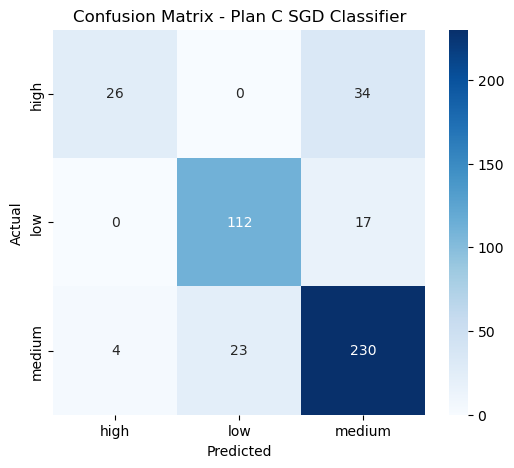

y_test_bin shape: (446, 3)
y_score shape: (446, 3)


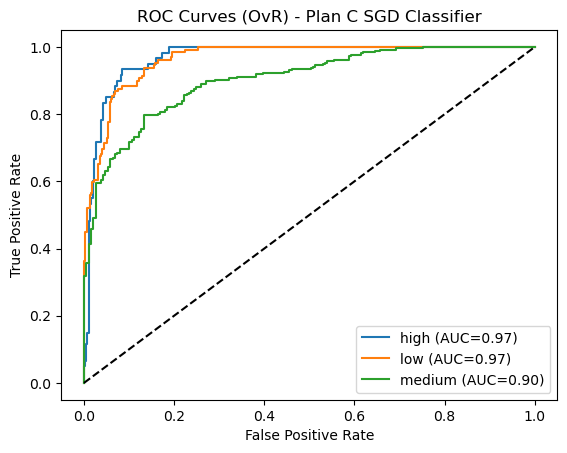

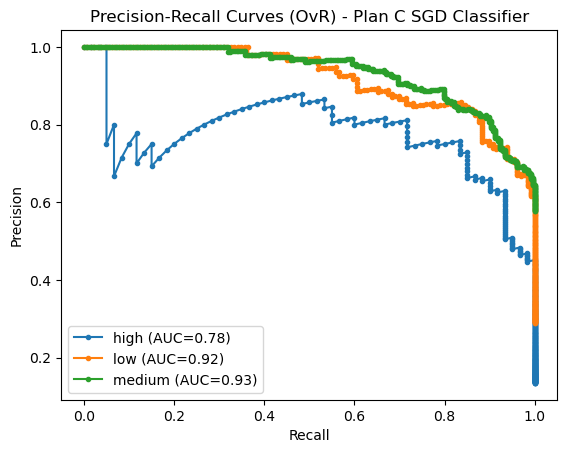


=== AUC Summary - Plan C SGD Classifier (OvR per class) ===


,ROC-AUC,PR-AUC
high,0.968,0.776
low,0.965,0.918
medium,0.902,0.931


In [56]:
# =========================================================
# Performance Visualization - Plan C (SGD Classifier) [Multi-class OvR]
# =========================================================
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc, precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import LabelEncoder, label_binarize
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from IPython.display import display

# --- Confusion Matrix ---
cm = confusion_matrix(y_test_C, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=np.unique(y_test_C), 
            yticklabels=np.unique(y_test_C))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Plan C SGD Classifier")
plt.show()

# ===============================
#  Encode labels consistently
# ===============================
le = LabelEncoder()
y_true_enc = le.fit_transform(y_test_C)        # numeric 0/1/2
classes = le.classes_                          # ['high','low','medium']

# Binarize labels (OvR)
y_test_bin = label_binarize(y_true_enc, classes=range(len(classes)))

# Predict probabilities (requires SGDClassifier with loss="log_loss")
y_score = final_model.predict_proba(X_test_C)

# Sanity check
print("y_test_bin shape:", y_test_bin.shape)
print("y_score shape:", y_score.shape)

summary = {}

# --- ROC Curves per class ---
plt.figure()
for i, class_label in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_label} (AUC={roc_auc:.2f})")
    summary[class_label] = {"ROC-AUC": float(roc_auc)}
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (OvR) - Plan C SGD Classifier")
plt.legend()
plt.show()

# --- PR Curves per class ---
plt.figure()
for i, class_label in enumerate(classes):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    pr_auc = average_precision_score(y_test_bin[:, i], y_score[:, i])
    plt.plot(recall, precision, marker='.', label=f"{class_label} (AUC={pr_auc:.2f})")
    summary[class_label]["PR-AUC"] = float(pr_auc)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves (OvR) - Plan C SGD Classifier")
plt.legend()
plt.show()

# --- Summary Table ---
df_auc = pd.DataFrame.from_dict(summary, orient="index")
print("\n=== AUC Summary - Plan C SGD Classifier (OvR per class) ===")
display(df_auc.round(3))


## 13. Learning Curve Analysis

The **learning curve** illustrates how the model’s performance evolves as the training dataset size increases.

### Components
1. **Training score**  
   - Accuracy on the **training set**.  
   - Very high training but low validation → indicates **overfitting**.  

2. **Validation score**  
   - Accuracy from **cross-validation** folds.  
   - Low training & validation → indicates **underfitting**.  

3. **Shaded area**  
   - ±1 standard deviation across folds → shows **model stability**.  

### Interpretation
- Large gap between training & validation = **overfitting**.  
- Small gap with plateau = **stable, well-generalized model**.  

### Purpose
- Confirms that the **final tuned model (Plan C SGD Clasifier)** is **well-trained and generalizes properly**, or reveals if more data/complexity tuning is required.


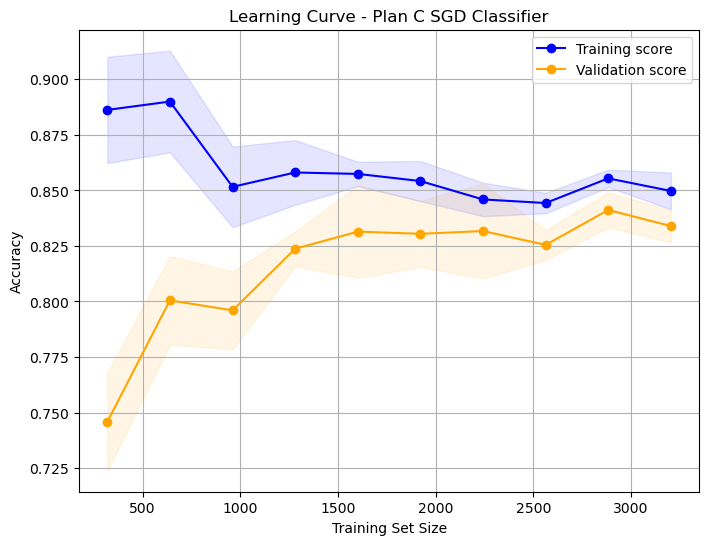

In [57]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Combine training and validation sets ---
X_train_full = pd.concat([X_train_C, X_val_C])
y_train_full = pd.concat([y_train_C, y_val_C])

# --- 2. Encode labels numerically (needed for SGD too, keeps consistency) ---
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train_full)

# --- 3. Generate learning curve with SGD Classifier ---
train_sizes, train_scores, val_scores = learning_curve(
    best_models_C["SGD Classifier"],   # use SGD instead of XGBoost
    X_train_full, 
    y_train_enc,
    cv=5, scoring='accuracy', n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10), shuffle=True, random_state=42
)

# --- 4. Compute mean and std ---
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

# --- 5. Plot learning curve ---
plt.figure(figsize=(8,6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training score')
plt.plot(train_sizes, val_mean, 'o-', color='orange', label='Validation score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='orange')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve - Plan C SGD Classifier')
plt.legend()
plt.grid(True)
plt.show()


# Conclusion

## Insights from the Learning Curve (Plan C: SGD Classifier)

### Training vs Validation Score
- **Training accuracy** starts high (~0.88–0.89) and gradually decreases slightly as the training size increases, stabilizing around **0.85**.  
- **Validation accuracy** starts lower (~0.74) and steadily increases with more training data, stabilizing around **0.83**.

### Gap Between Training and Validation
- The gap is moderate, around **0.02–0.03** toward the end.  
- This indicates **slight overfitting early on**, but as the dataset grows, the model **generalizes better**.

### Shaded Areas (±1 Std Dev)
- Both training and validation scores have relatively **narrow shaded regions**, suggesting **stable performance across folds**.

### Overall Interpretation
- The model **benefits from more data**, as validation accuracy increases with larger training size.  
- The final validation accuracy (\~0.83) is close to training accuracy (\~0.85), suggesting **good generalization**.  
- There’s **no severe overfitting or underfitting**, so the model is **well-tuned for deployment**.
